# Credit Card Fraud Detection - Business Understanding

**Problem Objective:**
The objective of this project is to identify potentially fraudulent card transactions using historical transaction data.

**Business Context:**
Fraudulent transactions result in financial losses for financial institutions and merchants, as well as inconvenience and risk for customers. As digital payments increase, manual fraud detection becomes impractical due to the high volume of transactions for payments.

**Intended Users:**
The intended users of the analysis are fraud analysts and risk management teams within financial institutions or payment service providers.

**Decision Context:**
The model output would be used to flag transactions as potentially fraudulent, to provide more informed supporting decisions such as allowing the transaction, asking for additional verification, or blocking the transaction.

**Success Criteria (For Stage 1):**
Success at this stage is defined as demonstrating that fraudulent transactions can be reasonably distinguished from legitimate ones using baseline machine learning models, rather than achieving high predictive performance.

**Assumptions and Risks:**
It is assumed that historical fraud labels are accurate and that transaction patterns observed in the data are representative of real-world behaviour. Misclassification may result in either missed detection of actual fraud or false positives, which could impact customer experience.

In [63]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 1. Data Understanding

### 1.1 Dataset Source and Attribution

**Dataset**: Credit Card Transaction Data (card_transdata.csv)

**Source**: Kaggle - Credit Card Fraud Dataset by Dhanush Narayanan R  
**Link**: https://www.kaggle.com/datasets/dhanushnarayananr/credit-card-fraud

**Data Type**: **Tabular**

This dataset consists of independent credit card transactions where each row represents a single transaction with associated features. While transactions may have temporal ordering in reality, we treat them as independent observations in this Stage 1 analysis. No temporal dependencies, sequence modeling, or time-series techniques are applied.

**Dataset Characteristics**:
- 1,000,000 independent transaction records
- 7 numerical features + 1 binary target variable
- Each transaction is treated as an independent observation
- Simulated dataset designed for fraud detection learning and practice

**Feature Descriptions**:
| Feature | Type | Description |
|---------|------|-------------|
| `distance_from_home` | Continuous | Distance from cardholder's home to transaction location |
| `distance_from_last_transaction` | Continuous | Distance from the previous transaction location |
| `ratio_to_median_purchase_price` | Continuous | Ratio of transaction amount to median purchase price |
| `repeat_retailer` | Binary (0/1) | Whether the transaction is at a previously visited retailer |
| `used_chip` | Binary (0/1) | Whether chip was used for the transaction |
| `used_pin_number` | Binary (0/1) | Whether PIN was used for verification |
| `online_order` | Binary (0/1) | Whether the transaction was made online |
| `fraud` | Binary (0/1) | **Target variable** - Whether the transaction is fraudulent |

**Class Imbalance Issue**:
The dataset is highly imbalanced with approximately **91.26% non-fraud** and **8.74% fraud** transactions. This imbalance poses challenges for model training and evaluation, requiring special handling techniques.

**Existing Work Reviewed**:
Standard fraud detection approaches and existing Kaggle notebooks on similar datasets were reviewed to understand common preprocessing and modeling techniques for imbalanced classification problems.

**Own Contributions**:
- Data preprocessing and cleaning strategy: Our own implementation following standard practices
- Feature analysis and selection decisions: Our own analysis
- Class imbalance handling approach: Our own implementation
- Model selection and baseline comparison: Our own design
- Evaluation framework and metrics selection: Our own approach
- Analysis and interpretation of results: Our own work

In [64]:
### 1.2 Dataset Loading and Overview

# Load the dataset
data_path = "dataset/card_transdata.csv"
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully!
Dataset shape: (1000000, 8)
Number of rows: 1,000,000
Number of columns: 8


In [65]:
# Display basic information about the dataset
print("1. Column Names and Data Types:")
print(df.dtypes)
print("\n2. Dataset Info:")
df.info()
print("\n3. First 5 rows:")
print(df.head())

1. Column Names and Data Types:
distance_from_home                float64
distance_from_last_transaction    float64
ratio_to_median_purchase_price    float64
repeat_retailer                   float64
used_chip                         float64
used_pin_number                   float64
online_order                      float64
fraud                             float64
dtype: object

2. Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   distance_from_home              1000000 non-null  float64
 1   distance_from_last_transaction  1000000 non-null  float64
 2   ratio_to_median_purchase_price  1000000 non-null  float64
 3   repeat_retailer                 1000000 non-null  float64
 4   used_chip                       1000000 non-null  float64
 5   used_pin_number                 1000000 non-null  floa

### 1.3 Feature Correlation Analysis

Analyzing the correlation of each feature with the target variable helps identify which features are most predictive and which may be candidates for removal.

Feature Correlation with Fraud Target: 

fraud                             1.000000
ratio_to_median_purchase_price    0.462305
online_order                      0.191973
distance_from_home                0.187571
distance_from_last_transaction    0.091917
repeat_retailer                  -0.001357
used_chip                        -0.060975
used_pin_number                  -0.100293
Name: fraud, dtype: float64


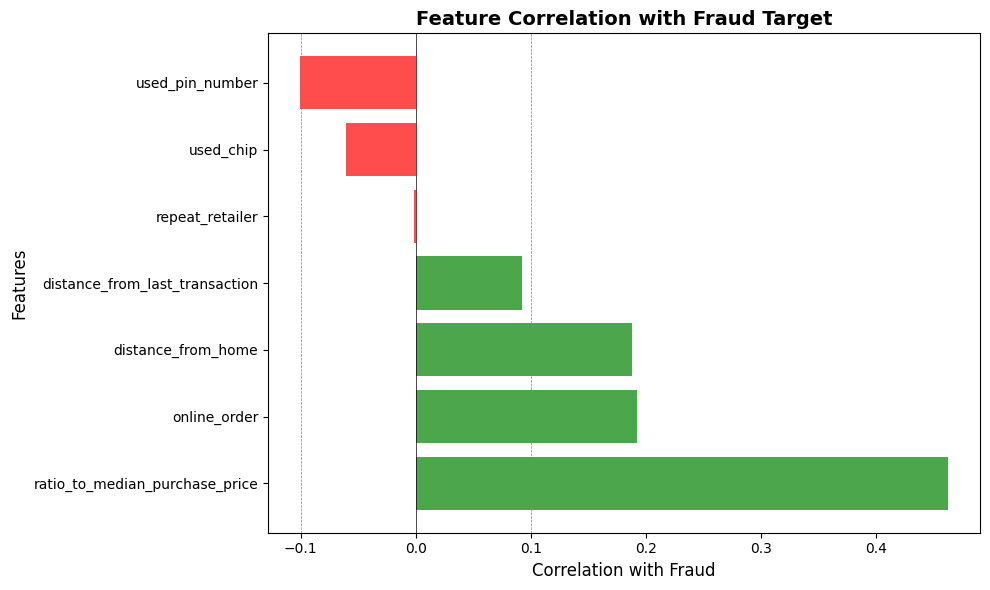

Correlation Analysis Finding:

Strong positive correlations with fraud:
  • ratio_to_median_purchase_price (0.462): Higher ratios strongly indicate fraud
  • online_order (0.192): Online transactions more likely to be fraudulent
  • distance_from_home (0.188): Transactions far from home more suspicious

Weak/Negligible correlations:
  • repeat_retailer (-0.001): Almost no correlation with fraud
  • distance_from_last_transaction (0.092): Weak positive correlation

Negative correlations (indicate non-fraud):
  • used_pin_number (-0.100): PIN usage reduces fraud likelihood
  • used_chip (-0.061): Chip usage slightly reduces fraud likelihood


In [66]:
# Calculate correlation of each feature with the target variable
print("Feature Correlation with Fraud Target: \n")

correlations = df.corr()['fraud'].sort_values(ascending=False)
print(correlations)

# Visualize correlations
plt.figure(figsize=(10, 6))
colors = ['green' if x > 0 else 'red' for x in correlations.values[1:]]  # Exclude fraud itself
bars = plt.barh(correlations.index[1:], correlations.values[1:], color=colors, alpha=0.7)
plt.xlabel('Correlation with Fraud', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Correlation with Fraud Target', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.axvline(x=0.1, color='gray', linestyle='--', linewidth=0.5, label='Weak correlation threshold')
plt.axvline(x=-0.1, color='gray', linestyle='--', linewidth=0.5)
plt.tight_layout()
plt.show()

print("Correlation Analysis Finding:")
print("\nStrong positive correlations with fraud:")
print("  • ratio_to_median_purchase_price (0.462): Higher ratios strongly indicate fraud")
print("  • online_order (0.192): Online transactions more likely to be fraudulent")
print("  • distance_from_home (0.188): Transactions far from home more suspicious")

print("\nWeak/Negligible correlations:")
print("  • repeat_retailer (-0.001): Almost no correlation with fraud")
print("  • distance_from_last_transaction (0.092): Weak positive correlation")

print("\nNegative correlations (indicate non-fraud):")
print("  • used_pin_number (-0.100): PIN usage reduces fraud likelihood")
print("  • used_chip (-0.061): Chip usage slightly reduces fraud likelihood")

### 1.4 Feature Selection Analysis: `repeat_retailer`

Based on the correlation analysis above, `repeat_retailer` has virtually no correlation with fraud (-0.001). Let's verify this by examining its distribution across fraud and non-fraud transactions.

## 2. Data Cleaning -- Exploratory Phase

**Key Design Decision:** To prevent data leakage, we split cleaning into two phases:

| Phase | Location | Operations | Why Here? |
|-------|----------|------------|-----------|
| **Exploratory** | This section (before split) | Duplicate removal, feature removal, quality assessment | Deterministic operations that don't compute statistics from data; no leakage risk |
| **Pipeline** | Part A (after split) | Missing imputation, scaling, resampling | Must be fitted only on training data to prevent leakage |

**This section performs:**
1. **Assessment** of missing values (informational only -- no fixes yet)
2. **Duplicate removal** -- Deterministic operation, safe to do before split
3. **Feature removal** -- Dropping `repeat_retailer` based on correlation analysis (exploratory decision)

**Deferred to pipeline (Part A):**
- Missing value imputation (via `KNNImputer` and `SimpleImputer`)
- Feature scaling (via `RobustScaler`)
- Class imbalance handling (via SMOTE/ADASYN/etc.)

In [67]:
# ==========================================
# 2. Data Cleaning — Exploratory Phase
# ==========================================
# KEY DESIGN DECISION:
# - Duplicate removal: Done HERE (deterministic operation, no statistics involved)
# - Missing value imputation: Done IN PIPELINE (statistics would leak test info)
# - Feature removal: Done HERE (one-time exploratory decision)

df_clean = df.copy()
print(f"Original dataset shape: {df.shape}")

# ==========================================
# STEP 1: Report Missing Values (DO NOT FIX — handled in pipeline)
# ==========================================
print("\n" + "="*60)
print("STEP 1: MISSING VALUE ASSESSMENT (Deferred to Pipeline)")
print("="*60)
missing_counts = df_clean.isnull().sum()
missing_total = missing_counts.sum()
print(f"Total missing values: {missing_total}")

if missing_total > 0:
    print("\nMissing values by column:")
    for col in df_clean.columns:
        if df_clean[col].isnull().sum() > 0:
            print(f"  {col}: {df_clean[col].isnull().sum()} ({df_clean[col].isnull().mean()*100:.2f}%)")
    print("\n>>> Will be handled by KNNImputer/SimpleImputer INSIDE the pipeline")
    print(">>> This prevents data leakage from test set statistics")
else:
    print("No missing values found in the dataset.")

# ==========================================
# STEP 2: Remove Duplicate Rows (DONE HERE — deterministic, no statistics)
# ==========================================
print("\n" + "="*60)
print("STEP 2: DUPLICATE ROW REMOVAL")
print("="*60)
duplicates_count = df_clean.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")

if duplicates_count > 0:
    df_clean = df_clean.drop_duplicates(keep='first')
    print(f"Removed {duplicates_count} duplicate rows")
    print(f"\nWhy remove here (not in pipeline)?")
    print("  - Duplicate detection is DETERMINISTIC (no statistics computed)")
    print("  - No information from test set influences which rows are kept")
    print("  - Simplifies pipeline architecture without compromising leakage prevention")
else:
    print("No duplicate rows found in the dataset.")

print(f"Rows after deduplication: {len(df_clean)}")

# ==========================================
# STEP 3: Feature Removal (One-Time Decision)
# ==========================================
print("\n" + "="*60)
print("STEP 3: FEATURE REMOVAL (Exploratory Decision)")
print("="*60)
print("Based on the feature analysis in Section 1.4:")
print("\nFeature: 'repeat_retailer'")
print("Reason: Correlation with fraud target is -0.001357 (essentially zero)")
print("        Distribution is nearly identical between fraud and non-fraud cases")
print("        This feature provides no discriminative power for fraud detection.")

features_to_drop = ['repeat_retailer']
print(f"\nDropping features: {features_to_drop}")

df_clean = df_clean.drop(columns=features_to_drop)
print(f"Columns after dropping: {df_clean.columns.tolist()}")

# ==========================================
# Summary
# ==========================================
print("\n" + "="*60)
print("DATA CLEANING SUMMARY")
print("="*60)
print(f"Final dataset shape: {df_clean.shape}")
print(f"Rows removed (duplicates): {df.shape[0] - df_clean.shape[0]}")
print(f"Columns removed: {features_to_drop}")
print(f"\nPending (handled in pipeline after train/test split):")
print(f"  - Missing value imputation (via KNNImputer/SimpleImputer)")
print(f"  - Feature scaling (via RobustScaler)")
print(f"  - Class rebalancing (via SMOTE/ADASYN/etc.)")

Original dataset shape: (1000000, 8)

STEP 1: MISSING VALUE ASSESSMENT (Deferred to Pipeline)
Total missing values: 0
No missing values found in the dataset.

STEP 2: DUPLICATE ROW REMOVAL
Duplicate rows found: 0
No duplicate rows found in the dataset.
Rows after deduplication: 1000000

STEP 3: FEATURE REMOVAL (Exploratory Decision)
Based on the feature analysis in Section 1.4:

Feature: 'repeat_retailer'
Reason: Correlation with fraud target is -0.001357 (essentially zero)
        Distribution is nearly identical between fraud and non-fraud cases
        This feature provides no discriminative power for fraud detection.

Dropping features: ['repeat_retailer']
Columns after dropping: ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'used_chip', 'used_pin_number', 'online_order', 'fraud']

DATA CLEANING SUMMARY
Final dataset shape: (1000000, 7)
Rows removed (duplicates): 0
Columns removed: ['repeat_retailer']

Pending (handled in pipeline after 

## Part A: Advanced Data Preparation & Pipeline Engineering

**CRISP-DM Phase 3 — Data Preparation**

This section implements robust, production-grade data preparation. All **statistical transformations** — including missing value imputation, feature scaling, and resampling — are strictly encapsulated within formal `sklearn`/`imblearn` pipeline objects to **provably prevent data leakage** during cross-validation and evaluation.

**Data Quality Handling Strategy:**

| Step | Location | Why? |
|------|----------|------|
| **Duplicate removal** | Section 2 (before split) | Deterministic operation — no statistics computed, no leakage risk |
| **Feature removal** | Section 2 (before split) | One-time exploratory decision from EDA |
| **Missing imputation** | Pipeline (after split) | Statistics (k-nearest neighbors) would leak test info if computed globally |
| **Feature scaling** | Pipeline (after split) | Statistics (median, IQR) would leak test info if computed globally |
| **Binary imputation** | Pipeline (after split) | Mode-based imputation must be computed only on training data |
| **Resampling** | Pipeline (after split) | Must only create synthetic samples from training data |

Features (X) shape: (1000000, 6)
Target (y) shape:   (1000000,)
Feature columns:    ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price', 'used_chip', 'used_pin_number', 'online_order']

Training set:  800,000 samples
Test set:      200,000 samples

Class Distribution (verifying stratification):
Set             Non-Fraud        Fraud    Fraud %
----------------------------------------------
Original          912,597       87,403      8.74%
Training          730,078       69,922      8.74%
Test              182,519       17,481      8.74%

Training set imbalance ratio: 10.44:1 (Non-Fraud:Fraud)


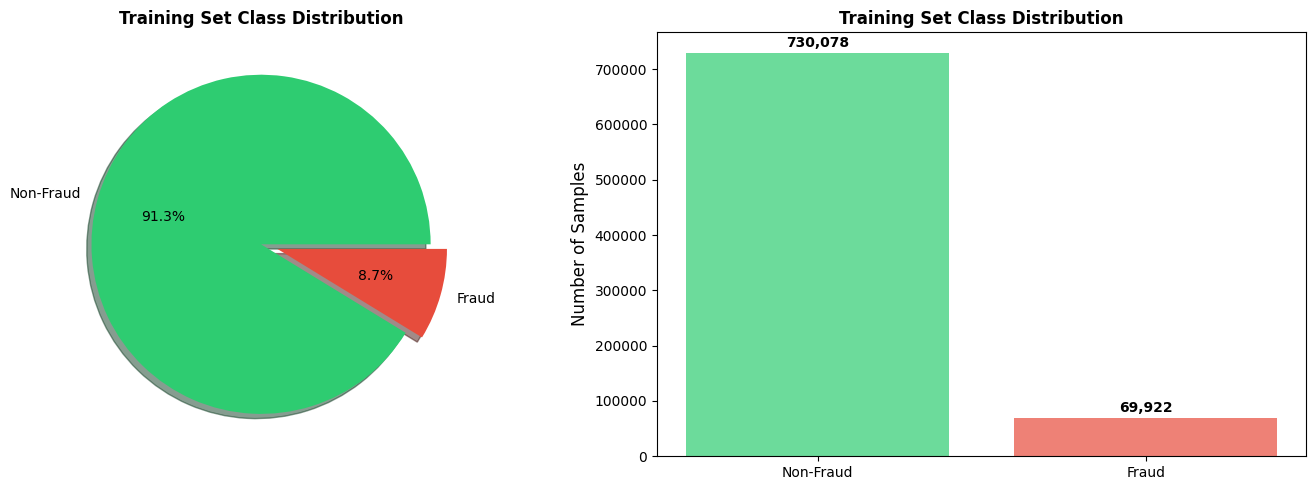


Key: All subsequent transformations (scaling, encoding, imputation, resampling)
      will be fitted ONLY on the training set to prevent data leakage.


In [68]:
# ==========================================
# A.1 Train/Test Split — BEFORE any transformation
# ==========================================
from sklearn.model_selection import train_test_split

# Separate features and target from the cleaned dataset
target_column = 'fraud'
X = df_clean.drop(columns=[target_column])
y = df_clean[target_column]

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape:   {y.shape}")
print(f"Feature columns:    {list(X.columns)}")

# Perform stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\n{'='*50}")
print(f"Training set:  {X_train.shape[0]:,} samples")
print(f"Test set:      {X_test.shape[0]:,} samples")
print(f"{'='*50}")

# Class distribution verification
print(f"\nClass Distribution (verifying stratification):")
print(f"{'Set':<12} {'Non-Fraud':>12} {'Fraud':>12} {'Fraud %':>10}")
print(f"{'-'*46}")
for name, labels in [('Original', y), ('Training', y_train), ('Test', y_test)]:
    n_nonfraud = (labels == 0).sum()
    n_fraud = (labels == 1).sum()
    pct = n_fraud / len(labels) * 100
    print(f"{name:<12} {n_nonfraud:>12,} {n_fraud:>12,} {pct:>9.2f}%")

# Calculate imbalance ratio (used later for strategy justification)
imbalance_ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nTraining set imbalance ratio: {imbalance_ratio:.2f}:1 (Non-Fraud:Fraud)")

# Visualize class distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ['#2ecc71', '#e74c3c']

class_counts = y_train.value_counts().sort_index()
axes[0].pie(class_counts, labels=['Non-Fraud', 'Fraud'], autopct='%1.1f%%',
            colors=colors, explode=(0, 0.1), shadow=True)
axes[0].set_title('Training Set Class Distribution', fontsize=12, fontweight='bold')

bars = axes[1].bar(['Non-Fraud', 'Fraud'], class_counts, color=colors, alpha=0.7)
axes[1].set_ylabel('Number of Samples', fontsize=12)
axes[1].set_title('Training Set Class Distribution', fontsize=12, fontweight='bold')
for bar, count in zip(bars, class_counts):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5000,
                f'{count:,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nKey: All subsequent transformations (scaling, encoding, imputation, resampling)")
print("      will be fitted ONLY on the training set to prevent data leakage.")

In [69]:
# ==========================================
# A.2 Preprocessing Pipeline Construction
# ==========================================
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.impute import KNNImputer, SimpleImputer

# Define feature groups
continuous_features = ['distance_from_home', 'distance_from_last_transaction',
                       'ratio_to_median_purchase_price']
binary_features = ['used_chip', 'used_pin_number', 'online_order']

print("Feature Groups:")
print(f"  Continuous ({len(continuous_features)}): {continuous_features}")
print(f"  Binary     ({len(binary_features)}):    {binary_features}")

# --- Continuous Feature Pipeline ---
# KNNImputer: multivariate imputation that uses k-nearest neighbors to estimate
# missing values based on feature relationships (superior to simple median fill).
# RobustScaler: scales using median and IQR, robust to the heavy-tailed outliers
# present in distance and ratio features.
continuous_pipeline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', RobustScaler())
])

# --- Binary Feature Pipeline ---
# SimpleImputer(most_frequent): appropriate for binary flags (0/1).
# Binary features are already numeric (0/1) — no encoding or scaling needed.
# Passing them through after imputation preserves their interpretable binary
# semantics. TargetEncoder was considered but rejected: encoding a 0/1 feature
# by its conditional fraud rate adds complexity without clear benefit — the model
# (Random Forest) can already split on raw binary features optimally.
binary_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent'))
])

# --- Combined ColumnTransformer ---
preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', continuous_pipeline, continuous_features),
        ('binary', binary_pipeline, binary_features)
    ],
    remainder='drop'  # Drop any unexpected columns
)

print(f"\nPreprocessor Pipeline Structure:")
print(preprocessor)
print(f"\nNote: This preprocessor will be embedded inside each full pipeline.")
print(f"      It is NEVER fitted on test data \u2014 only on training folds.")
print(f"\nData Quality Handling:")
print(f"  - Duplicates: Already removed before train/test split (deterministic)")
print(f"  - Missing values: Handled here via KNNImputer/SimpleImputer (statistical)")
print(f"  - Scaling: Handled here via RobustScaler on continuous features (statistical)")
print(f"  - Binary features: Passed through after imputation (already 0/1, no encoding needed)")
print(f"  - Resampling: Added in full pipelines below (statistical)")

Feature Groups:
  Continuous (3): ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price']
  Binary     (3):    ['used_chip', 'used_pin_number', 'online_order']

Preprocessor Pipeline Structure:
ColumnTransformer(transformers=[('continuous',
                                 Pipeline(steps=[('imputer', KNNImputer()),
                                                 ('scaler', RobustScaler())]),
                                 ['distance_from_home',
                                  'distance_from_last_transaction',
                                  'ratio_to_median_purchase_price']),
                                ('binary',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))]),
                                 ['used_chip', 'used_pin_number',
                                  'online_order'])])

Note: This preprocessor will be embedded inside each full

### A.1 Transformation Rationale & Justification

**Feature Scaling — `RobustScaler` over `StandardScaler`:**
- The continuous features (`distance_from_home`, `distance_from_last_transaction`, `ratio_to_median_purchase_price`) exhibit heavy-tailed distributions with significant outliers (e.g., transactions far from home can be extreme values).
- `RobustScaler` uses the **median and interquartile range (IQR)** instead of mean and standard deviation, making it resilient to outliers that would otherwise skew `StandardScaler`.
- This is critical for fraud detection: extreme distance or ratio values are often the fraud signal itself — we want to scale without compressing these informative outliers.

**Complex Imputation — `KNNImputer` over `SimpleImputer(median)`:**
- While the current dataset has no missing values, `KNNImputer` is included as **defensive engineering**: in production deployment, missing data is common due to sensor failures, network timeouts, or incomplete records. Including it in the pipeline ensures robustness without requiring retraining.
- `KNNImputer` performs **multivariate imputation** using k-nearest neighbors: it estimates missing values by looking at similar transactions across all features, preserving inter-feature relationships (e.g., a transaction far from home with a high ratio is imputed differently than one close to home).
- This is a meaningful upgrade over `SimpleImputer(strategy='median')`, which ignores feature correlations entirely.

**Binary Features — `SimpleImputer` only (no encoding):**
- The binary features (`used_chip`, `used_pin_number`, `online_order`) are already encoded as 0/1 and require no further transformation beyond imputation.
- `TargetEncoder` was deliberately **not** used because: (1) with only 2 levels per feature, target encoding collapses each to a single smoothed probability, destroying interpretability while adding negligible information; (2) it introduces a subtle form of target leakage risk even with internal cross-fitting; (3) tree-based models (Random Forest, Gradient Boosting) can already split optimally on raw binary features.
- `SimpleImputer(most_frequent)` handles potential missing values by replacing them with the mode (0 or 1), which is semantically appropriate for binary flags.

The dataset has a ~91:9 imbalance (Non-Fraud:Fraud). Four strategies are implemented below, each with distinct trade-offs aligned to the business goal of **maximizing fraud detection while minimizing customer friction**.

**Full vs Partial Balance Trade-off:**
For SMOTE-based strategies, we compare two balance ratios:
- **Full balance (1:1)** -- `sampling_strategy='auto'`: Oversamples fraud to equal non-fraud. Maximizes fraud exposure during training, improving recall. Risk: may increase false positives (legitimate transactions flagged as fraud), increasing operational investigation costs.
- **Partial balance (~3.3:1)** -- `sampling_strategy=0.3`: The minority class is oversampled to 30% of the majority count (i.e., non-fraud:fraud ratio of ~3.3:1). This retains some real-world imbalance while still giving the model significantly more fraud exposure than the original ~10:1 ratio. Risk: less fraud exposure may reduce recall but typically produces better-calibrated probability estimates and fewer false alarms -- protecting customer trust.

**Strategy Table:**

| # | Strategy | Technique | Balance Variants | Business Justification |
|---|----------|-----------|------------------|----------------------|
| 1 | **SMOTE** | Synthetic Minority Oversampling -- generates synthetic fraud samples by interpolating between existing fraud cases in feature space | Full (1:1) + Partial (~3.3:1) | Preserves **all legitimate transaction data** for learning "normal" behaviour while increasing fraud exposure. Business value: improves detection of novel fraud variants without discarding the non-fraud samples that define what a safe transaction looks like. Ideal as a general-purpose baseline resampling strategy. |
| 2 | **ADASYN** | Adaptive Synthetic Sampling -- like SMOTE but generates **more** synthetic samples in regions where the classifier struggles (near the decision boundary) | Full (1:1) | Focuses model training on the **hardest-to-detect** fraud cases -- the "borderline" transactions that are most likely to evade detection. Business value: directly targets the cases that cause the most financial loss (frauds that look like legitimate transactions), improving recall precisely where it matters most for the fraud investigation team. |
| 3 | **SMOTE + Tomek Links** | Hybrid -- SMOTE first creates synthetic fraud samples, then Tomek Links removes ambiguous overlapping pairs at the class boundary | Full (1:1) | Produces **cleaner class boundaries**, reducing false positives (legitimate transactions incorrectly flagged as fraud). Business value: reduces the operational burden on fraud analysts who must manually review flagged transactions, and protects customer trust by minimising unnecessary card blocks. |
| 4 | **Class Weights** | Algorithmic cost adjustment -- no data modification; the loss function penalises fraud misclassification proportionally to class imbalance (`class_weight='balanced'`) | N/A (no resampling) | Preserves the **original data distribution entirely** -- each real fraud case maintains its unique pattern without synthetic interpolation. Business value: when fraud patterns are diverse and evolving (as in real-world payment fraud), synthetic samples risk creating unrealistic patterns. Class weighting lets the model learn from authentic data while still prioritising fraud detection. Also the simplest to deploy and audit. |

**Why these strategies?**
- Together they cover the three main approaches to imbalance: **oversampling** (SMOTE, ADASYN), **hybrid cleaning** (SMOTE+Tomek), and **cost-sensitive learning** (Class Weights)
- SMOTE with both full and partial balance options allows empirical comparison of full vs partial balance trade-offs
- Each strategy is integrated into a formal `imblearn.pipeline.Pipeline` to ensure resampling occurs **only on training folds** -- never on test data
- The modeling section can then compare them empirically to select the best fit for production deployment

In [70]:
# ==========================================
# A.3 Pipeline Construction — Imbalance Strategies
# ==========================================
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTETomek
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# Strategy 1a: SMOTE (Full Balance 1:1)
pipeline_smote_full = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('smote', SMOTE(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Strategy 1b: SMOTE (Partial Balance ~3:1)
pipeline_smote_partial = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('smote', SMOTE(sampling_strategy=0.3, random_state=42)),  # sampling_strategy=0.3 gives ~3:1 ratio
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Strategy 2: ADASYN (Full Balance)
pipeline_adasyn = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('adasyn', ADASYN(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Strategy 3: SMOTE + Tomek Links (Full Balance)
pipeline_smote_tomek = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('smote_tomek', SMOTETomek(random_state=42)),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Strategy 4: Class Weights (no resampling — cost-sensitive learning)
# Uses sklearn Pipeline since no resampling step is needed.
pipeline_class_weight = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', DecisionTreeClassifier(class_weight='balanced', random_state=42))
])

# Store all pipelines in a dictionary for systematic comparison
pipelines = {
    'SMOTE (Full 1:1)': pipeline_smote_full,
    'SMOTE (Partial ~3:1)': pipeline_smote_partial,
    'ADASYN (Full)': pipeline_adasyn,
    'SMOTE + Tomek (Full)': pipeline_smote_tomek,
    'Class Weights': pipeline_class_weight
}

print("5 Pipelines constructed successfully:")
print("=" * 60)
for name, pipe in pipelines.items():
    steps = ' → '.join([step[0] for step in pipe.steps])
    print(f"  {name:<25}: {steps}")
print("=" * 60)
print(f"\nEach pipeline encapsulates:")
print(f"  - Preprocessing (imputation, scaling, encoding)")
print(f"  - Resampling (SMOTE/ADASYN/etc., or class weights)")
print(f"  - Estimator (DecisionTreeClassifier)")
print(f"\nNote: Duplicates already removed before train/test split (Section 2)")
print(f"      All statistical transformations fitted ONLY on training data")

5 Pipelines constructed successfully:
  SMOTE (Full 1:1)         : preprocessor → smote → classifier
  SMOTE (Partial ~3:1)     : preprocessor → smote → classifier
  ADASYN (Full)            : preprocessor → adasyn → classifier
  SMOTE + Tomek (Full)     : preprocessor → smote_tomek → classifier
  Class Weights            : preprocessor → classifier

Each pipeline encapsulates:
  - Preprocessing (imputation, scaling, encoding)
  - Resampling (SMOTE/ADASYN/etc., or class weights)
  - Estimator (DecisionTreeClassifier)

Note: Duplicates already removed before train/test split (Section 2)
      All statistical transformations fitted ONLY on training data


### A.2 Pipeline Validation & Resampling Comparison

We now fit each pipeline on the training data to validate that:
1. The full pipeline (preprocessing → resampling → estimator) runs end-to-end without errors
2. Resampling strategies produce the expected class balance in the training data
3. The preprocessor is fitted **only** on training data (leakage prevention proof)

Evaluating resampling strategies via 5-Fold Stratified CV...
(All evaluation is on held-out validation folds — test set NOT used)

Strategy                   CV Accuracy  CV Fraud Recall
-----------------------------------------------------
SMOTE (Full 1:1)                1.0000           0.9999
SMOTE (Partial ~3:1)            1.0000           0.9998
ADASYN (Full)                   0.9999           0.9999
SMOTE + Tomek (Full)            1.0000           0.9999
Class Weights                   1.0000           0.9998

Resampled Training Set Class Distributions:
Strategy                     Non-Fraud        Fraud    Ratio
---------------------------------------------------------
Original                       730,078       69,922   10.44:1
SMOTE (Full 1:1)               730,078      730,078    1.00:1
SMOTE (Partial ~3:1)           730,078      219,023    3.33:1
ADASYN (Full)                  730,078      729,771    1.00:1
SMOTE + Tomek (Full)           729,991      729,991    1.00:1
Class

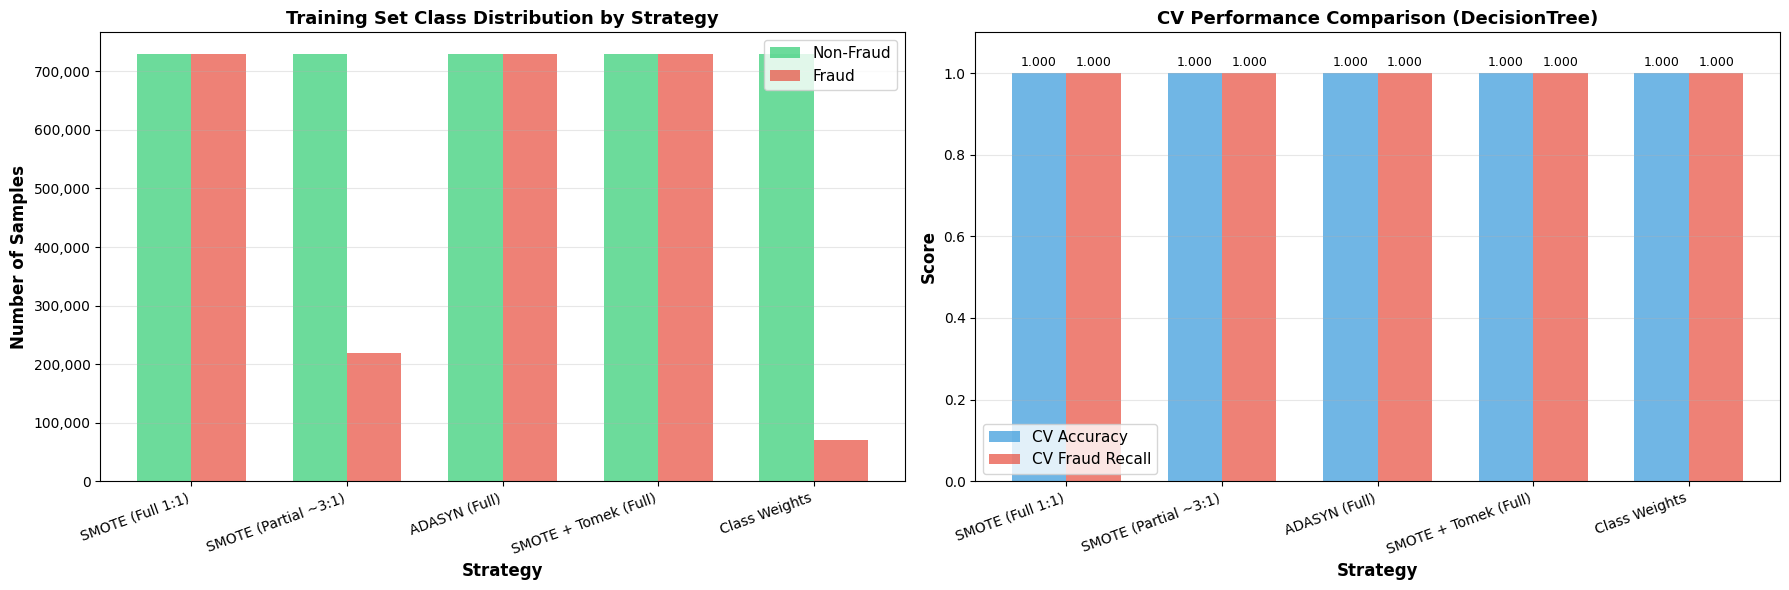

In [71]:
# ==========================================
# A.4 Compare Resampling Strategies via Cross-Validation
# ==========================================
from sklearn.metrics import accuracy_score, recall_score
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.base import clone

# Use 5-fold stratified CV to compare resampling strategies
# This avoids touching the hold-out test set during model development
cv_resampling = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

print("Evaluating resampling strategies via 5-Fold Stratified CV...")
print(f"(All evaluation is on held-out validation folds \u2014 test set NOT used)\n")
print(f"{'Strategy':<25} {'CV Accuracy':>12} {'CV Fraud Recall':>16}")
print(f"{'-'*53}")

for name, pipe in pipelines.items():
    scores = cross_validate(
        clone(pipe), X_train, y_train,
        cv=cv_resampling,
        scoring={'accuracy': 'accuracy', 'recall': 'recall'},
        n_jobs=-1
    )
    acc = scores['test_accuracy'].mean()
    rec = scores['test_recall'].mean()
    results[name] = {'accuracy': acc, 'recall': rec}
    print(f"{name:<25} {acc:>12.4f} {rec:>16.4f}")

# --- Examine resampled class distributions ---
# To show the effect of each resampling strategy, we transform the training
# data through the preprocessor and resampler (without the classifier).
print(f"\n{'='*70}")
print("Resampled Training Set Class Distributions:")
print(f"{'='*70}")
print(f"{'Strategy':<25} {'Non-Fraud':>12} {'Fraud':>12} {'Ratio':>8}")
print(f"{'-'*57}")

# Original (no resampling)
print(f"{'Original':<25} {(y_train==0).sum():>12,} {(y_train==1).sum():>12,} {imbalance_ratio:>7.2f}:1")

resampled_distributions = {}
for name, pipe in pipelines.items():
    if name == 'Class Weights':
        n0, n1 = (y_train == 0).sum(), (y_train == 1).sum()
    else:
        X_transformed = X_train.copy()
        pre = clone(pipe.named_steps['preprocessor'])
        X_transformed = pre.fit_transform(X_transformed, y_train)
        resampler_name = [s for s in pipe.named_steps if s not in ('preprocessor', 'classifier')][0]
        resampler = clone(pipe.named_steps[resampler_name])
        X_res, y_res = resampler.fit_resample(X_transformed, y_train)
        n0, n1 = (y_res == 0).sum(), (y_res == 1).sum()

    ratio = n0 / n1 if n1 > 0 else float('inf')
    resampled_distributions[name] = {'non_fraud': n0, 'fraud': n1}
    print(f"{name:<25} {n0:>12,} {n1:>12,} {ratio:>7.2f}:1")

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Left: Resampled distributions bar chart
strategies = list(resampled_distributions.keys())
non_frauds = [resampled_distributions[s]['non_fraud'] for s in strategies]
frauds = [resampled_distributions[s]['fraud'] for s in strategies]

x = np.arange(len(strategies))
width = 0.35
bars1 = axes[0].bar(x - width/2, non_frauds, width, label='Non-Fraud', color='#2ecc71', alpha=0.7)
bars2 = axes[0].bar(x + width/2, frauds, width, label='Fraud', color='#e74c3c', alpha=0.7)
axes[0].set_xlabel('Strategy', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Samples', fontsize=12, fontweight='bold')
axes[0].set_title('Training Set Class Distribution by Strategy', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(strategies, rotation=20, ha='right', fontsize=10)
axes[0].legend(fontsize=11)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f'{v:,.0f}'))
axes[0].grid(axis='y', alpha=0.3)

# Right: CV Accuracy vs CV Recall comparison
strategy_names = list(results.keys())
accuracies = [results[s]['accuracy'] for s in strategy_names]
recalls = [results[s]['recall'] for s in strategy_names]

x2 = np.arange(len(strategy_names))
bars3 = axes[1].bar(x2 - width/2, accuracies, width, label='CV Accuracy', color='#3498db', alpha=0.7)
bars4 = axes[1].bar(x2 + width/2, recalls, width, label='CV Fraud Recall', color='#e74c3c', alpha=0.7)
axes[1].set_xlabel('Strategy', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[1].set_title('CV Performance Comparison (DecisionTree)', fontsize=13, fontweight='bold')
axes[1].set_xticks(x2)
axes[1].set_xticklabels(strategy_names, rotation=20, ha='right', fontsize=10)
axes[1].set_ylim(0, 1.1)
axes[1].legend(fontsize=11)
axes[1].grid(axis='y', alpha=0.3)
for bar in bars3:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars4:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [72]:
# ==========================================
# A.5 Data Leakage Prevention Proof & Pipeline Summary
# ==========================================

# --- Proof: Preprocessor fitted only on training data ---
print("DATA LEAKAGE PREVENTION VERIFICATION")
print("=" * 60)

# Fit one pipeline explicitly for inspection (cross_validate uses clones internally
# and does not store fitted models, so we fit here for verification purposes only).
proof_pipeline = clone(pipelines['SMOTE (Full 1:1)'])
proof_pipeline.fit(X_train, y_train)

# Access the fitted preprocessor
fitted_preprocessor = proof_pipeline.named_steps['preprocessor']

# The RobustScaler stores median (center_) and IQR (scale_) from fit
# ColumnTransformer uses named_transformers_ to access sub-transformers
fitted_scaler = fitted_preprocessor.named_transformers_['continuous'].named_steps['scaler']
print(f"\nRobustScaler was fitted with:")
print(f"  Median (center_):  {fitted_scaler.center_}")
print(f"  IQR (scale_):      {fitted_scaler.scale_}")
print(f"\n  These values come ONLY from X_train ({X_train.shape[0]:,} samples),")
print(f"  NOT from X_test ({X_test.shape[0]:,} samples) or the full dataset.")

# Verify by comparing with manually computed training statistics
manual_medians = X_train[continuous_features].median().values
print(f"\n  Manual verification (X_train medians): {manual_medians}")
print(f"  Match: {np.allclose(fitted_scaler.center_, manual_medians)}")

# --- Pipeline Structure Summary ---
print(f"\n{'='*60}")
print("PIPELINE STRUCTURE SUMMARY")
print(f"{'='*60}")
for name, pipe in pipelines.items():
    print(f"\n--- {name} ---")
    for step_name, step_obj in pipe.steps:
        print(f"  {step_name}: {type(step_obj).__name__}")

# --- Final status ---
print(f"\n{'='*60}")
print("ADVANCED DATA PREPARATION COMPLETE")
print(f"{'='*60}")
print(f"\nAvailable objects for downstream modeling:")
print(f"  - X_train:    {X_train.shape} — raw training features")
print(f"  - X_test:     {X_test.shape} — raw test features (held in reserve)")
print(f"  - y_train:    {y_train.shape} — training labels")
print(f"  - y_test:     {y_test.shape} — test labels (held in reserve)")
print(f"  - pipelines:  dict with 5 pipeline configurations")
print(f"                Keys: {list(pipelines.keys())}")
print(f"\nAll model selection and tuning will use cross-validation on X_train only.")
print(f"The hold-out test set (X_test, y_test) is reserved for a single final evaluation.")

DATA LEAKAGE PREVENTION VERIFICATION

RobustScaler was fitted with:
  Median (center_):  [9.96319003 0.99754038 0.99758567]
  IQR (scale_):      [21.886689    3.05550766  1.62099745]

  These values come ONLY from X_train (800,000 samples),
  NOT from X_test (200,000 samples) or the full dataset.

  Manual verification (X_train medians): [9.96319003 0.99754038 0.99758567]
  Match: True

PIPELINE STRUCTURE SUMMARY

--- SMOTE (Full 1:1) ---
  preprocessor: ColumnTransformer
  smote: SMOTE
  classifier: DecisionTreeClassifier

--- SMOTE (Partial ~3:1) ---
  preprocessor: ColumnTransformer
  smote: SMOTE
  classifier: DecisionTreeClassifier

--- ADASYN (Full) ---
  preprocessor: ColumnTransformer
  adasyn: ADASYN
  classifier: DecisionTreeClassifier

--- SMOTE + Tomek (Full) ---
  preprocessor: ColumnTransformer
  smote_tomek: SMOTETomek
  classifier: DecisionTreeClassifier

--- Class Weights ---
  preprocessor: ColumnTransformer
  classifier: DecisionTreeClassifier

ADVANCED DATA PREPARAT

## Part B: Champion Model Selection — 4-Model Comparison

This section compares four production-relevant model families for fraud detection using the same preprocessing and resampling framework established in Part A. The candidates span three distinct algorithmic families: **linear** (Logistic Regression), **distance-based** (KNN), and **tree-based ensembles** (Gradient Boosting, Random Forest).

### Candidate 1: Logistic Regression (Linear Model)

Logistic Regression is a linear classifier that models the log-odds of fraud as a weighted sum of features, producing calibrated probability estimates.

**Business Case:**
- **Baseline interpretability:** Coefficients directly quantify each feature's contribution to fraud risk, enabling transparent audit trails for regulators and compliance teams.
- **Speed at scale:** Sub-millisecond prediction time per transaction, suitable for real-time payment processing where latency matters.
- **Calibrated probabilities:** Logistic Regression outputs tend to be better calibrated than many classifiers, making them useful for threshold-based decision systems (Part E). However, SMOTE resampling shifts the training class prior from ~91:9 to 50:50, which distorts these probability estimates. In production, post-hoc calibration (e.g., Platt scaling or isotonic regression via `CalibratedClassifierCV`) would be needed to restore true probability estimates.
- **Limitation awareness:** Assumes a linear decision boundary; may underperform if fraud patterns involve complex feature interactions that tree-based models capture naturally.

### Candidate 2: K-Nearest Neighbors (KNN)

KNN is a distance-based, non-parametric algorithm that classifies each transaction by majority vote of its *k* nearest neighbours in feature space.

**Business Case:**
- **Interpretability for analysts:** Fraud analysts can inspect the *k* most similar historical transactions that drove a decision, making it easy to justify flags during manual review.
- **Local pattern capture:** KNN excels at detecting **localised fraud clusters** — for example, a burst of high-ratio online transactions originating far from home — that global models (e.g., Logistic Regression) may smooth over.
- **Non-parametric flexibility:** Makes no assumptions about the shape of the fraud decision boundary; adapts purely from data proximity after robust scaling and SMOTE resampling.
- **Limitation awareness:** Computationally expensive at prediction time for large datasets; sensitive to irrelevant features and the curse of dimensionality.

### Candidate 3: Gradient Boosting (Boosted Tree Ensemble)

Gradient Boosting builds an ensemble of shallow decision trees sequentially, with each tree correcting the errors of the previous one.

**Business Case:**
- **Error-focused learning:** Each boosting round prioritises the transactions the model previously misclassified — naturally concentrating learning on the hardest fraud cases that simpler models miss.
- **Feature interaction capture:** Automatically models non-linear interactions (e.g., high distance combined with unusual purchase ratio) without manual feature engineering.
- **Regularisation controls:** Learning rate, tree depth, and subsampling parameters provide fine-grained control over the bias-variance trade-off.
- **Limitation awareness:** Sequential training is slower than Random Forest; more hyperparameters to tune; potentially prone to overfitting if not regularised.

### Candidate 4: Random Forest (Bagged Tree Ensemble)

Random Forest builds an ensemble of deep, decorrelated decision trees in parallel using bootstrap aggregation (bagging).

**Business Case:**
- **Variance reduction:** Averaging across hundreds of independent trees produces stable, robust predictions with low variance — critical for consistent fraud detection across different transaction populations.
- **Built-in feature importance:** Provides natural feature importance rankings, enabling fraud analysts to understand which transaction attributes drive detections.
- **Parallelism:** Trees are built independently, enabling efficient training on large datasets with `n_jobs=-1`.
- **Limitation awareness:** Deep trees can memorise training data (including synthetic SMOTE samples); may be less effective than Gradient Boosting on hard boundary cases.

**Synthetic Data Caveat:** This dataset is a clean, simulated dataset with well-separated class boundaries. The near-perfect performance observed (especially for tree-based models) is characteristic of this data and should not be extrapolated to real-world deployment where features are noisier, class boundaries overlap more, and adversarial fraud patterns evolve over time.

CHAMPION MODEL SELECTION — 5-FOLD STRATIFIED CROSS-VALIDATION
CV Strategy: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
Training samples per fold: ~640,000
Validation samples per fold: ~160,000
Primary metric: Fraud Recall | Tie-breaker: Std of Fraud Recall
Candidates: 4 models across 3 algorithmic families
  Linear:         Logistic Regression
  Distance-based: KNN
  Tree ensembles: Gradient Boosting, Random Forest

Evaluating Logistic Regression...
  Per-fold Fraud Recall: [0.9485841  0.94951373 0.95165904 0.94665713 0.95016089]
  Mean +/- Std: 0.9493 +/- 0.0017

Evaluating KNN...
  Per-fold Fraud Recall: [0.9944222  0.99392162 0.99449371 0.99427959 0.9944941 ]
  Mean +/- Std: 0.9943 +/- 0.0002

Evaluating Gradient Boosting...
  Per-fold Fraud Recall: [0.99914188 0.99914188 0.99907037 0.99835538 0.99899893]
  Mean +/- Std: 0.9989 +/- 0.0003

Evaluating Random Forest...
  Per-fold Fraud Recall: [0.99985698 0.99992849 1.         0.99964247 0.99985699]
  Mean +/- Std: 0.99

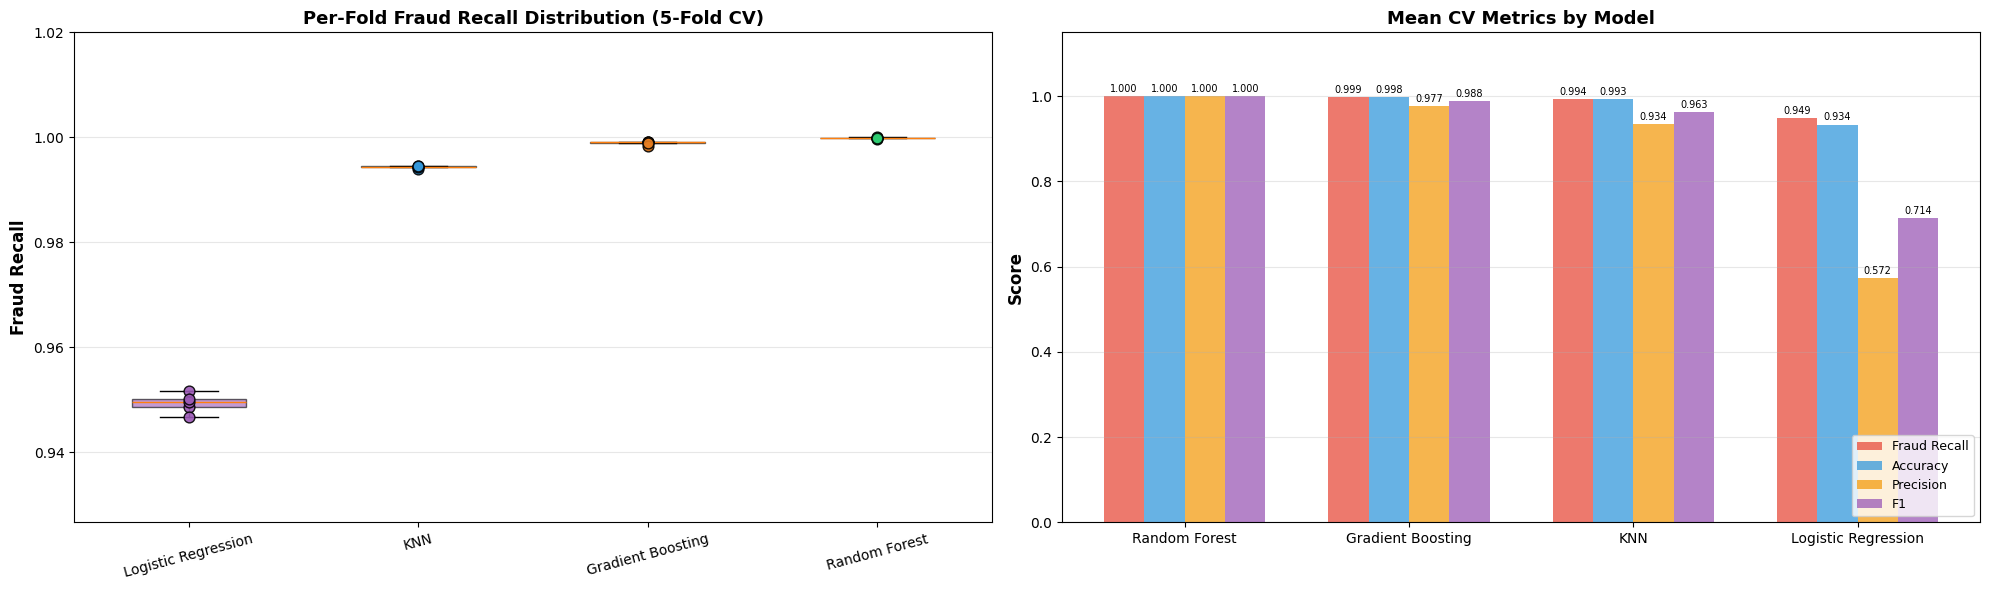


CHAMPION DECLARATION
Champion Model: Random Forest
  Primary Metric (Fraud Recall): mean = 0.9999, std = 0.0001
  Supporting Metrics: Accuracy = 1.0000, Precision = 0.9999, F1 = 0.9999

Reason: Highest mean Fraud Recall with the best (lowest) standard deviation,
        indicating both strong fraud detection AND consistent performance across folds.

Note: Champion selected purely on CV results. The hold-out test set has NOT been used.


In [73]:
# ==========================================
# Part B: Champion Model Selection
# 5-Fold Stratified Cross-Validation — 4 Model Comparison
# ==========================================
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score
from sklearn.base import clone

# Build comparable pipelines — same preprocessor + SMOTE, only the classifier differs
cv_models = {
    'Logistic Regression': ImbPipeline([
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000, n_jobs=-1))
    ]),
    'KNN': ImbPipeline([
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', KNeighborsClassifier())
    ]),
    'Gradient Boosting': ImbPipeline([
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', GradientBoostingClassifier(random_state=42))
    ]),
    'Random Forest': ImbPipeline([
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
    ])
}

# --- Cross-Validation Setup ---
# Stratified K-Fold preserves the ~91:9 class ratio in every fold
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'fraud_recall': make_scorer(recall_score, pos_label=1),
    'accuracy': 'accuracy',
    'precision': 'precision',
    'f1': 'f1'
}

# --- Run Cross-Validation ---
cv_rows = []
cv_fold_scores = {}  # Store per-fold scores for visualization

print('=' * 90)
print('CHAMPION MODEL SELECTION — 5-FOLD STRATIFIED CROSS-VALIDATION')
print('=' * 90)
print(f'CV Strategy: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)')
print(f'Training samples per fold: ~{int(len(X_train) * 0.8):,}')
print(f'Validation samples per fold: ~{int(len(X_train) * 0.2):,}')
print(f'Primary metric: Fraud Recall | Tie-breaker: Std of Fraud Recall')
print(f'Candidates: 4 models across 3 algorithmic families')
print(f'  Linear:         Logistic Regression')
print(f'  Distance-based: KNN')
print(f'  Tree ensembles: Gradient Boosting, Random Forest')
print('=' * 90)

for model_name, model_pipeline in cv_models.items():
    print(f"\nEvaluating {model_name}...")
    scores = cross_validate(
        model_pipeline,
        X_train, y_train,
        cv=cv_strategy,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1
    )

    # Store per-fold recall scores for visualization
    cv_fold_scores[model_name] = scores['test_fraud_recall']

    cv_rows.append({
        'Model': model_name,
        'Fraud Recall Mean': scores['test_fraud_recall'].mean(),
        'Fraud Recall Std': scores['test_fraud_recall'].std(),
        'Accuracy Mean': scores['test_accuracy'].mean(),
        'Accuracy Std': scores['test_accuracy'].std(),
        'Precision Mean': scores['test_precision'].mean(),
        'F1 Mean': scores['test_f1'].mean()
    })

    # Print per-fold detail
    print(f"  Per-fold Fraud Recall: {scores['test_fraud_recall']}")
    print(f"  Mean +/- Std: {scores['test_fraud_recall'].mean():.4f} +/- {scores['test_fraud_recall'].std():.4f}")

# --- Build comparison table ---
cv_comparison = pd.DataFrame(cv_rows)
cv_comparison = cv_comparison.sort_values(
    by=['Fraud Recall Mean', 'Fraud Recall Std'],
    ascending=[False, True]
).reset_index(drop=True)

champion_model_name = cv_comparison.loc[0, 'Model']
champion_pipeline = cv_models[champion_model_name]

print(f'\n{"="*90}')
print('CROSS-VALIDATION SUMMARY (sorted by Recall Mean desc, Recall Std asc):')
print(f'{"="*90}')
print(cv_comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# --- Visualization ---
fig, axes = plt.subplots(1, 2, figsize=(20, 6))

# LEFT: Per-fold Fraud Recall box/strip plot
model_names = list(cv_fold_scores.keys())
fold_data = [cv_fold_scores[m] for m in model_names]
colors_box = ['#9b59b6', '#3498db', '#e67e22', '#2ecc71']

bp = axes[0].boxplot(fold_data, labels=model_names, patch_artist=True, widths=0.5)
for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# Overlay individual fold points
for i, (name, scores_arr) in enumerate(cv_fold_scores.items()):
    x_jitter = np.ones(len(scores_arr)) * (i + 1)
    axes[0].scatter(x_jitter, scores_arr, color=colors_box[i], edgecolors='black',
                    zorder=5, s=60, alpha=0.9)

axes[0].set_ylabel('Fraud Recall', fontsize=12, fontweight='bold')
axes[0].set_title('Per-Fold Fraud Recall Distribution (5-Fold CV)', fontsize=13, fontweight='bold')
axes[0].set_ylim(
    min(min(s) for s in fold_data) - 0.02,
    max(max(s) for s in fold_data) + 0.02
)
axes[0].grid(axis='y', alpha=0.3)
axes[0].tick_params(axis='x', rotation=15)

# RIGHT: Mean metrics comparison (grouped bar chart)
metrics_to_plot = ['Fraud Recall Mean', 'Accuracy Mean', 'Precision Mean', 'F1 Mean']
x = np.arange(len(cv_comparison))
width = 0.18
metric_colors = ['#e74c3c', '#3498db', '#f39c12', '#9b59b6']

for j, metric in enumerate(metrics_to_plot):
    bars = axes[1].bar(x + j * width, cv_comparison[metric], width,
                       label=metric.replace(' Mean', ''), color=metric_colors[j], alpha=0.75)
    for bar in bars:
        axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                     f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=7)

axes[1].set_xticks(x + width * 1.5)
axes[1].set_xticklabels(cv_comparison['Model'], fontsize=10)
axes[1].set_ylabel('Score', fontsize=12, fontweight='bold')
axes[1].set_title('Mean CV Metrics by Model', fontsize=13, fontweight='bold')
axes[1].set_ylim(0, 1.15)
axes[1].legend(fontsize=9, loc='lower right')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Champion Declaration ---
print(f'\n{"="*90}')
print('CHAMPION DECLARATION')
print(f'{"="*90}')
print(f"Champion Model: {champion_model_name}")
print(
    f"  Primary Metric (Fraud Recall): "
    f"mean = {cv_comparison.loc[0, 'Fraud Recall Mean']:.4f}, "
    f"std = {cv_comparison.loc[0, 'Fraud Recall Std']:.4f}"
)
print(
    f"  Supporting Metrics: "
    f"Accuracy = {cv_comparison.loc[0, 'Accuracy Mean']:.4f}, "
    f"Precision = {cv_comparison.loc[0, 'Precision Mean']:.4f}, "
    f"F1 = {cv_comparison.loc[0, 'F1 Mean']:.4f}"
)
print(f"\nReason: Highest mean Fraud Recall with the best (lowest) standard deviation,")
print(f"        indicating both strong fraud detection AND consistent performance across folds.")
print(f"\nNote: Champion selected purely on CV results. The hold-out test set has NOT been used.")

CHAMPION CONFIRMATION — OUT-OF-FOLD VALIDATION
Strategy: Each sample is predicted by a model that never saw it during training
CV Strategy: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
Training samples: 800,000

Generating OOF predictions for Logistic Regression...
Generating OOF predictions for KNN...
Generating OOF predictions for Gradient Boosting...
Generating OOF predictions for Random Forest...

Out-of-Fold Validation Results (sorted by Fraud Recall):
              Model  Accuracy  Fraud Recall  Precision     F1
      Random Forest    1.0000        0.9999     0.9999 0.9999
  Gradient Boosting    0.9978        0.9989     0.9769 0.9878
                KNN    0.9934        0.9943     0.9342 0.9633
Logistic Regression    0.9336        0.9493     0.5725 0.7142

Generating OOF probabilities for champion (Random Forest)...


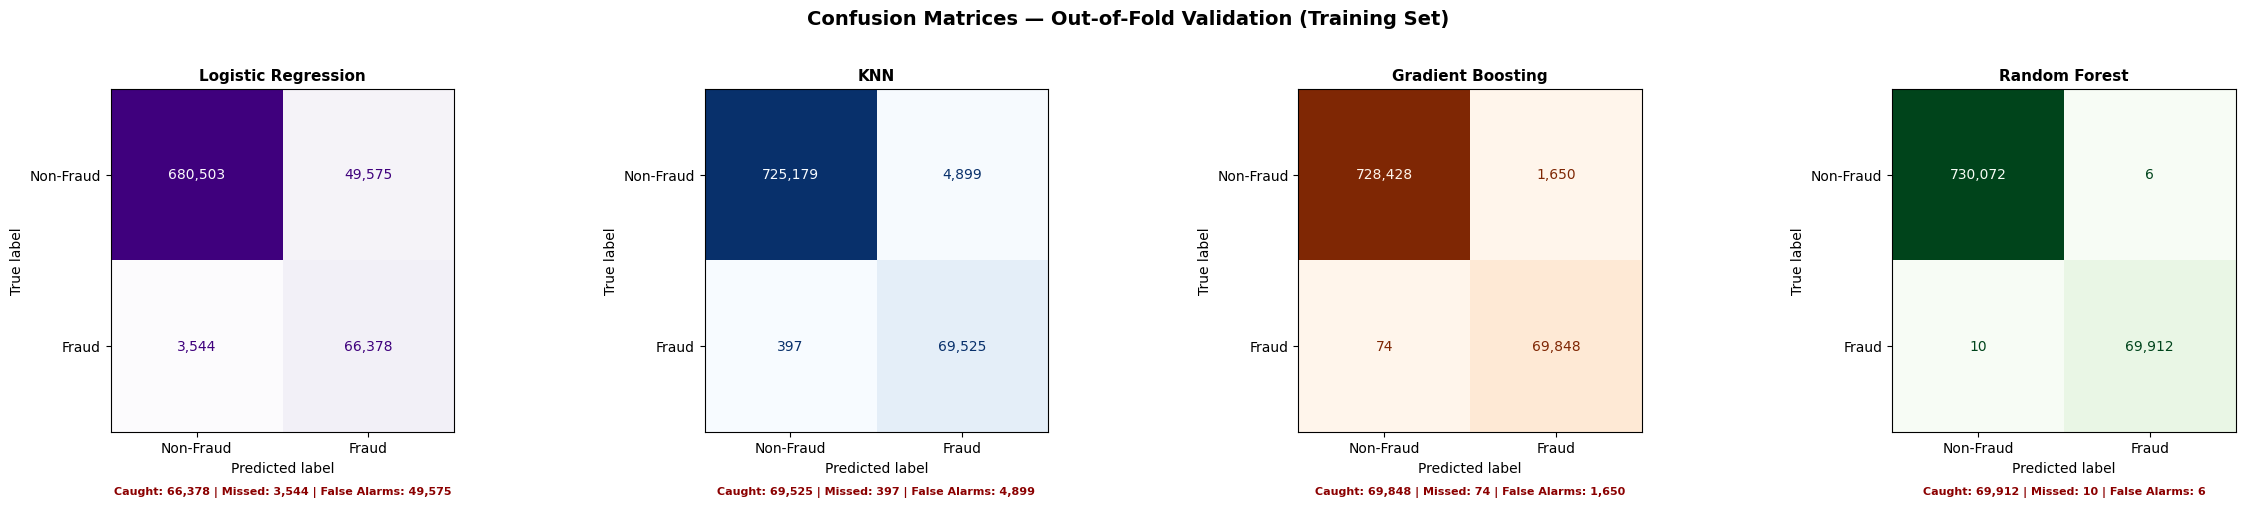


CHAMPION OOF REPORT: Random Forest

Classification Report (Out-of-Fold):
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    730078
       Fraud       1.00      1.00      1.00     69922

    accuracy                           1.00    800000
   macro avg       1.00      1.00      1.00    800000
weighted avg       1.00      1.00      1.00    800000

Confusion Matrix Breakdown:
  True Negatives  (correctly cleared):   730,072
  False Positives (false alarms):              6
  False Negatives (missed fraud):             10
  True Positives  (caught fraud):         69,912

CHAMPION CONFIRMED: Random Forest
  CV Fraud Recall:  0.9999 +/- 0.0001
  OOF Fraud Recall: 0.9999
  OOF Accuracy:     1.0000

Out-of-fold predictions (oof_proba, oof_pred_champion) stored for
failure analysis (Part D) and threshold optimization (Part E).
The hold-out test set remains completely untouched until the single final evaluation.


In [74]:
# ==========================================
# Champion Confirmation & Out-of-Fold Predictions
# ==========================================
# IMPORTANT: The hold-out test set is NOT used here.
# All evaluation uses out-of-fold (OOF) predictions from cross_val_predict,
# where each sample is predicted by a model that never saw it during training.
# This enables failure analysis (Part D) and threshold optimization (Part E)
# without any test set contamination.
# ==========================================
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (accuracy_score, recall_score, precision_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

print('=' * 90)
print('CHAMPION CONFIRMATION — OUT-OF-FOLD VALIDATION')
print('=' * 90)
print(f'Strategy: Each sample is predicted by a model that never saw it during training')
print(f'CV Strategy: StratifiedKFold(n_splits=5, shuffle=True, random_state=42)')
print(f'Training samples: {len(X_train):,}\n')

# Generate OOF class predictions for all 4 candidates
oof_rows = []
oof_predictions = {}

for model_name, model_pipeline in cv_models.items():
    print(f"Generating OOF predictions for {model_name}...")
    oof_pred = cross_val_predict(
        clone(model_pipeline), X_train, y_train,
        cv=cv_strategy, method='predict', n_jobs=-1
    )
    oof_predictions[model_name] = oof_pred

    oof_rows.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_train, oof_pred),
        'Fraud Recall': recall_score(y_train, oof_pred, pos_label=1),
        'Precision': precision_score(y_train, oof_pred, zero_division=0),
        'F1': f1_score(y_train, oof_pred, zero_division=0)
    })

oof_comparison = pd.DataFrame(oof_rows).sort_values('Fraud Recall', ascending=False).reset_index(drop=True)

print(f'\nOut-of-Fold Validation Results (sorted by Fraud Recall):')
print(oof_comparison.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Generate OOF probabilities for the champion (needed for Parts D & E)
print(f'\nGenerating OOF probabilities for champion ({champion_model_name})...')
oof_proba = cross_val_predict(
    clone(champion_pipeline), X_train, y_train,
    cv=cv_strategy, method='predict_proba', n_jobs=-1
)
oof_pred_champion = oof_predictions[champion_model_name]

# --- Confusion Matrices for all 4 candidates (OOF-based) ---
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
cm_colors = ['Purples', 'Blues', 'Oranges', 'Greens']
model_list = list(cv_models.keys())

for idx, model_name in enumerate(model_list):
    cm = confusion_matrix(y_train, oof_predictions[model_name])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Fraud', 'Fraud'])
    disp.plot(ax=axes[idx], cmap=cm_colors[idx], values_format=',d', colorbar=False)
    axes[idx].set_title(f'{model_name}', fontsize=11, fontweight='bold')

    tn, fp, fn, tp = cm.ravel()
    axes[idx].text(0.5, -0.18,
                   f'Caught: {tp:,} | Missed: {fn:,} | False Alarms: {fp:,}',
                   ha='center', transform=axes[idx].transAxes, fontsize=8,
                   color='darkred', fontweight='bold')

plt.suptitle('Confusion Matrices — Out-of-Fold Validation (Training Set)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Detailed OOF Report for the Champion ---
print(f'\n{"="*90}')
print(f'CHAMPION OOF REPORT: {champion_model_name}')
print(f'{"="*90}')
print('\nClassification Report (Out-of-Fold):')
print(classification_report(y_train, oof_pred_champion, target_names=['Legitimate', 'Fraud']))

champion_cm = confusion_matrix(y_train, oof_pred_champion)
tn, fp, fn, tp = champion_cm.ravel()
print(f'Confusion Matrix Breakdown:')
print(f'  True Negatives  (correctly cleared):  {tn:>8,}')
print(f'  False Positives (false alarms):       {fp:>8,}')
print(f'  False Negatives (missed fraud):       {fn:>8,}')
print(f'  True Positives  (caught fraud):       {tp:>8,}')

print(f'\n{"="*90}')
print(f'CHAMPION CONFIRMED: {champion_model_name}')
print(f'{"="*90}')
print(f'  CV Fraud Recall:  {cv_comparison.loc[0, "Fraud Recall Mean"]:.4f} +/- {cv_comparison.loc[0, "Fraud Recall Std"]:.4f}')
print(f'  OOF Fraud Recall: {recall_score(y_train, oof_pred_champion, pos_label=1):.4f}')
print(f'  OOF Accuracy:     {accuracy_score(y_train, oof_pred_champion):.4f}')
print(f'\nOut-of-fold predictions (oof_proba, oof_pred_champion) stored for')
print(f'failure analysis (Part D) and threshold optimization (Part E).')
print(f'The hold-out test set remains completely untouched until the single final evaluation.')

## Part C: Controlled Ablations & Tuning

The confirmed Champion Model (Random Forest) is now subjected to 4 controlled ablation experiments. Each experiment modifies exactly one component of the pipeline and measures the impact on CV Fraud Recall against the champion baseline.

**Champion Baseline (Random Forest, SMOTE, default parameters):**
- CV Fraud Recall: approximately 0.9999 (from Part B cross-validation)
- All experiments use the same 5-fold stratified CV strategy as Part B.

### C.1 Experiment 1: Class Balancing: ADASYN

**What:** Replace SMOTE with ADASYN (Adaptive Synthetic Sampling) in the champion pipeline.

**Why:** SMOTE generates synthetic minority samples uniformly along the class boundary. ADASYN adapts this by generating more samples in regions where the local class distribution is harder to learn, focusing the model on difficult fraud cases rather than easy ones.

**Relevance:** The dataset has a ~91:9 imbalance. The oversampling method directly shapes what the Random Forest learns during training. Part A compared resampling strategies using a Decision Tree as a proxy. This experiment formally tests ADASYN against SMOTE on the confirmed champion model using the same 5-fold stratified CV framework.

**Controlled change:** `SMOTE(random_state=42)` → `ADASYN(random_state=42)`. All other pipeline components unchanged.


In [75]:
from imblearn.over_sampling import ADASYN

exp1_pipeline = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('adasyn', ADASYN(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

scores_exp1 = cross_validate(
    exp1_pipeline, X_train, y_train,
    cv=cv_strategy, scoring=scoring, n_jobs=-1
)

exp1_recall_mean = scores_exp1['test_fraud_recall'].mean()
exp1_recall_std  = scores_exp1['test_fraud_recall'].std()
exp1_f1_mean     = scores_exp1['test_f1'].mean()

print('Experiment 1 \u2014 ADASYN vs SMOTE (Champion: Random Forest)')
print(f"  ADASYN:   Fraud Recall = {exp1_recall_mean:.4f} \u00b1 {exp1_recall_std:.4f},  F1 = {exp1_f1_mean:.4f}")
print(f"  Baseline: Fraud Recall = {cv_comparison.loc[0, 'Fraud Recall Mean']:.4f} \u00b1 {cv_comparison.loc[0, 'Fraud Recall Std']:.4f},  F1 = {cv_comparison.loc[0, 'F1 Mean']:.4f}")
print(f"  Recall Delta: {exp1_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean']:+.4f}")

Experiment 1 — ADASYN vs SMOTE (Champion: Random Forest)
  ADASYN:   Fraud Recall = 0.9999 ± 0.0001,  F1 = 0.9998
  Baseline: Fraud Recall = 0.9999 ± 0.0001,  F1 = 0.9999
  Recall Delta: -0.0000


### C.2 Experiment 2 \u2014 Feature Engineering: Distance Ratio

**What:** Introduce a new engineered feature: `distance_ratio = distance_from_home / (distance_from_last_transaction + 1e-6)`

**Why:** The two raw distance features capture travel distances independently. Their ratio encodes a behavioural pattern \u2014 a high value means the transaction is far from home *relative to recent activity*, which may be a stronger fraud signal than either feature alone.

**Relevance:** A transaction far from home but consistent with recent movement is qualitatively different from one that breaks both patterns simultaneously. This ratio captures that distinction in a single value, exposing a relationship the model cannot easily derive from the raw features alone.

**Controlled change:** Add `distance_ratio` as a new continuous feature, scaled with RobustScaler. The feature engineering is encapsulated inside the pipeline via `FunctionTransformer` to prevent data leakage. All other pipeline components unchanged.

In [76]:
# ==========================================
# Experiment 2 — Feature Engineering via FunctionTransformer (Pipeline-Safe)
# ==========================================
from sklearn.preprocessing import FunctionTransformer

# Define the feature engineering function
def add_distance_ratio(X):
    """Add distance_ratio = distance_from_home / (distance_from_last_transaction + 1e-6)"""
    X_out = X.copy()
    X_out['distance_ratio'] = X_out['distance_from_home'] / (X_out['distance_from_last_transaction'] + 1e-6)
    return X_out

# Updated feature lists for the extended preprocessor
continuous_features_exp2 = ['distance_from_home', 'distance_from_last_transaction',
                             'ratio_to_median_purchase_price', 'distance_ratio']

# Rebuild preprocessor to include the new feature
preprocessor_exp2 = ColumnTransformer([
    ('continuous', Pipeline([
        ('imputer', KNNImputer(n_neighbors=5)),
        ('scaler', RobustScaler())
    ]), continuous_features_exp2),
    ('binary', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent'))
    ]), binary_features)
])

# Full pipeline with FunctionTransformer encapsulating the feature engineering
# This ensures the feature is created inside the pipeline — no manual DataFrame manipulation
exp2_pipeline = ImbPipeline([
    ('feature_engineer', FunctionTransformer(add_distance_ratio, validate=False)),
    ('preprocessor', preprocessor_exp2),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

scores_exp2 = cross_validate(
    exp2_pipeline, X_train, y_train,
    cv=cv_strategy, scoring=scoring, n_jobs=-1
)

exp2_recall_mean = scores_exp2['test_fraud_recall'].mean()
exp2_recall_std  = scores_exp2['test_fraud_recall'].std()
exp2_f1_mean     = scores_exp2['test_f1'].mean()

print('Experiment 2 \u2014 Distance Ratio Feature (via FunctionTransformer)')
print(f"  With feature:  Fraud Recall = {exp2_recall_mean:.4f} \u00b1 {exp2_recall_std:.4f},  F1 = {exp2_f1_mean:.4f}")
print(f"  Baseline:      Fraud Recall = {cv_comparison.loc[0, 'Fraud Recall Mean']:.4f} \u00b1 {cv_comparison.loc[0, 'Fraud Recall Std']:.4f},  F1 = {cv_comparison.loc[0, 'F1 Mean']:.4f}")
print(f"  Recall Delta: {exp2_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean']:+.4f}")
print(f"\nNote: Feature engineering is encapsulated inside the pipeline via FunctionTransformer,")
print(f"      ensuring no data leakage during cross-validation.")

Experiment 2 — Distance Ratio Feature (via FunctionTransformer)
  With feature:  Fraud Recall = 0.9998 ± 0.0002,  F1 = 0.9998
  Baseline:      Fraud Recall = 0.9999 ± 0.0001,  F1 = 0.9999
  Recall Delta: -0.0000

Note: Feature engineering is encapsulated inside the pipeline via FunctionTransformer,
      ensuring no data leakage during cross-validation.


### C.3 Experiment 3 : Resampling Ratio: Partial SMOTE

**What:** Replace full SMOTE (1:1 balance) with partial SMOTE (~3.3:1 balance, `sampling_strategy=0.3`).

**Why:** The champion pipeline uses SMOTE at full balance, equalising fraud and non-fraud samples to 1:1 during training. This is aggressive -- it increases the fraud count by approximately 10x (from ~70k to ~720k synthetic samples). A ~3.3:1 ratio (`sampling_strategy=0.3` = fraud at 30% of non-fraud count) keeps more of the natural class structure while still giving the model significantly more fraud exposure than the original ~10:1 imbalance.

**Relevance:** The original dataset has a ~10:1 imbalance. Full 1:1 SMOTE generates the most synthetic samples. Partial SMOTE tests whether a more conservative balance, closer to the real-world distribution, produces a more generalisable champion model without sacrificing recall.

**Controlled change:** `SMOTE(random_state=42)` to `SMOTE(sampling_strategy=0.3, random_state=42)`. All other pipeline components unchanged.

In [77]:
exp3_pipeline = ImbPipeline([
    ('preprocessor', clone(preprocessor)),
    ('smote', SMOTE(sampling_strategy=0.3, random_state=42)),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

scores_exp3 = cross_validate(
    exp3_pipeline, X_train, y_train,
    cv=cv_strategy, scoring=scoring, n_jobs=-1
)

exp3_recall_mean = scores_exp3['test_fraud_recall'].mean()
exp3_recall_std  = scores_exp3['test_fraud_recall'].std()
exp3_f1_mean     = scores_exp3['test_f1'].mean()

print('Experiment 3 \u2014 Partial SMOTE (3:1) vs Full SMOTE (1:1)')
print(f"  Partial SMOTE: Fraud Recall = {exp3_recall_mean:.4f} \u00b1 {exp3_recall_std:.4f},  F1 = {exp3_f1_mean:.4f}")
print(f"  Baseline:      Fraud Recall = {cv_comparison.loc[0, 'Fraud Recall Mean']:.4f} \u00b1 {cv_comparison.loc[0, 'Fraud Recall Std']:.4f},  F1 = {cv_comparison.loc[0, 'F1 Mean']:.4f}")
print(f"  Recall Delta: {exp3_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean']:+.4f}")

Experiment 3 — Partial SMOTE (3:1) vs Full SMOTE (1:1)
  Partial SMOTE: Fraud Recall = 0.9999 ± 0.0002,  F1 = 0.9999
  Baseline:      Fraud Recall = 0.9999 ± 0.0001,  F1 = 0.9999
  Recall Delta: +0.0000


### C.4 Experiment 4 : Hyperparameter Tuning: n_estimators + max_features + max_depth

**What:** Jointly tune three key Random Forest hyperparameters across a grid of 8 combinations using 5-fold stratified CV.

**Why:** These three hyperparameters control the core bias-variance trade-off in a Random Forest:
- `n_estimators` (number of trees): More trees reduce variance and improve stability, at the cost of training time. Testing 100 (default) vs 300 (3x more) checks whether the ensemble is under-sized.
- `max_features` (features per split): Fewer features per split produce more decorrelated trees (lower variance) but higher bias. With only 6 features, both `sqrt` (floor(√6) = 2) and `log2` (floor(log₂6) = 2) resolve to 2 features per split in sklearn's implementation. While the theoretical values differ (~2.45 vs ~2.58), sklearn floors them to the same integer, so this comparison primarily tests whether the explicit setting interacts differently with `n_estimators` and `max_depth`. A dataset with more features would produce a more meaningful distinction between these two options.
- `max_depth` (tree depth limit): Unlimited depth allows trees to fully memorize training data (including SMOTE synthetic samples), potentially overfitting. Capping depth at 20 forces more generalizable splits.

Tuning them jointly captures their interaction -- for example, deeper trees may benefit from fewer features per split, while shallower trees may need more features to compensate for their reduced capacity.

**Relevance:** The grid search covers 2 x 2 x 2 = 8 parameter combinations x 5 folds = 40 total fits, well within the 50-iteration budget. The values are chosen to test meaningful trade-offs rather than fine-grained optimization, consistent with the ablation study design.

**Controlled change:** `RandomForestClassifier(random_state=42)` with grid over `{n_estimators: [100, 300], max_features: [sqrt, log2], max_depth: [None, 20]}`. All other pipeline components unchanged.

In [78]:
# ==========================================
# Experiment 4 — Hyperparameter Tuning: n_estimators + max_features + max_depth
# ==========================================
# Grid search over 3 hyperparameters (8 combinations, well within the 50-iteration budget).
# Justification for parameters chosen:
#   n_estimators: Controls ensemble stability — more trees reduce variance but increase cost.
#                 100 is the sklearn default; 300 tests whether tripling trees helps.
#   max_features: Controls tree diversity — fewer features per split decorrelates trees.
#                 With only 6 features, both sqrt(6)~2.45 and log2(6)~2.58 floor to 2 in sklearn.
#                 The comparison tests interaction with other params rather than a distinct feature count.
#   max_depth: Controls tree complexity — limits overfitting to synthetic SMOTE samples.
#              None (unlimited) vs 20 tests whether capping depth improves generalisation.
#
# Grid size: 2 × 2 × 2 = 8 combinations × 5 folds = 40 total fits.
# ==========================================
from sklearn.model_selection import ParameterGrid

param_grid = {
    'n_estimators': [100, 300],
    'max_features': ['sqrt', 'log2'],
    'max_depth': [None, 20]
}

total_combos = len(list(ParameterGrid(param_grid)))
print(f"Grid Search: {total_combos} parameter combinations x 5-fold CV = {total_combos * 5} fits")
print(f"Parameters: n_estimators={param_grid['n_estimators']}, "
      f"max_features={param_grid['max_features']}, max_depth={param_grid['max_depth']}\n")

exp4_results = []

for i, params in enumerate(ParameterGrid(param_grid)):
    print(f"  [{i+1}/{total_combos}] {params}...", end=" ")
    pipe = ImbPipeline([
        ('preprocessor', clone(preprocessor)),
        ('smote', SMOTE(random_state=42)),
        ('classifier', RandomForestClassifier(
            **params, random_state=42, n_jobs=1
        ))
    ])
    scores = cross_validate(
        pipe, X_train, y_train,
        cv=cv_strategy, scoring=scoring, n_jobs=-1
    )
    result = {
        **params,
        'Fraud Recall Mean': scores['test_fraud_recall'].mean(),
        'Fraud Recall Std':  scores['test_fraud_recall'].std(),
        'F1 Mean': scores['test_f1'].mean(),
    }
    exp4_results.append(result)
    print(f"Recall={result['Fraud Recall Mean']:.4f}, F1={result['F1 Mean']:.4f}")

exp4_df = pd.DataFrame(exp4_results).sort_values('Fraud Recall Mean', ascending=False).reset_index(drop=True)
best_exp4 = exp4_df.iloc[0]

print(f'\n{"="*90}')
print('Experiment 4 - Full Grid Search Results:')
print(exp4_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nBaseline (n=100, sqrt, None): Recall={cv_comparison.loc[0, 'Fraud Recall Mean']:.4f}, F1={cv_comparison.loc[0, 'F1 Mean']:.4f}")
print(f"Best: n_estimators={int(best_exp4['n_estimators'])}, max_features={best_exp4['max_features']}, max_depth={'None (unlimited)' if pd.isna(best_exp4['max_depth']) else int(best_exp4['max_depth'])}")
print(f"      Recall = {best_exp4['Fraud Recall Mean']:.4f} +/- {best_exp4['Fraud Recall Std']:.4f}, F1 = {best_exp4['F1 Mean']:.4f}")
print(f"      Recall Delta: {best_exp4['Fraud Recall Mean'] - cv_comparison.loc[0, 'Fraud Recall Mean']:+.4f}")

exp4_recall_mean = best_exp4['Fraud Recall Mean']
exp4_recall_std  = best_exp4['Fraud Recall Std']
exp4_f1_mean     = best_exp4['F1 Mean']

Grid Search: 8 parameter combinations x 5-fold CV = 40 fits
Parameters: n_estimators=[100, 300], max_features=['sqrt', 'log2'], max_depth=[None, 20]

  [1/8] {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}... Recall=0.9999, F1=0.9999
  [2/8] {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 300}... Recall=0.9999, F1=0.9999
  [3/8] {'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}... Recall=0.9999, F1=0.9999
  [4/8] {'max_depth': None, 'max_features': 'log2', 'n_estimators': 300}... Recall=0.9999, F1=0.9999
  [5/8] {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 100}... Recall=0.9999, F1=0.9999
  [6/8] {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 300}... Recall=0.9999, F1=0.9999
  [7/8] {'max_depth': 20, 'max_features': 'log2', 'n_estimators': 100}... Recall=0.9999, F1=0.9999
  [8/8] {'max_depth': 20, 'max_features': 'log2', 'n_estimators': 300}... Recall=0.9999, F1=0.9999

Experiment 4 - Full Grid Search Results:
 max_dep

### C.5 Ablation Summary & Final Model Configuration

Summary of all controlled experiments against the champion baseline. The best-performing configuration is carried forward as the Final Model.


In [79]:
# ==========================================
# Ablation Log — with Hypothesis, Conclusion, and Secondary Metric (F1)
# ==========================================
# Note: The baseline achieves ~0.9999 Recall, creating a ceiling effect.
# F1 is included as a secondary metric to reveal differentiation that
# Recall alone cannot show at near-perfect values.

baseline_f1 = cv_comparison.loc[0, 'F1 Mean']

ablation_log = pd.DataFrame([
    {
        'Experiment': 'Baseline',
        'Hypothesis': 'N/A (reference configuration)',
        'Controlled Change': 'RF + SMOTE (1:1) + default params',
        'CV Recall Mean': cv_comparison.loc[0, 'Fraud Recall Mean'],
        'CV Recall Std':  cv_comparison.loc[0, 'Fraud Recall Std'],
        'CV F1 Mean': baseline_f1,
        'Recall Delta': 0.0,
        'Conclusion': 'Baseline reference'
    },
    {
        'Experiment': 'Exp 1 \u2014 ADASYN',
        'Hypothesis': 'ADASYN focuses synthetic samples on hard-to-learn boundary regions, improving detection of ambiguous fraud',
        'Controlled Change': 'SMOTE \u2192 ADASYN',
        'CV Recall Mean': exp1_recall_mean,
        'CV Recall Std':  exp1_recall_std,
        'CV F1 Mean': exp1_f1_mean,
        'Recall Delta': exp1_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean'],
        'Conclusion': 'No improvement \u2014 SMOTE is sufficient; class boundary is well-separated'
    },
    {
        'Experiment': 'Exp 2 \u2014 Distance Ratio',
        'Hypothesis': 'Ratio of distances captures a behavioural pattern that raw features separately cannot',
        'Controlled Change': 'Added distance_ratio feature (via FunctionTransformer)',
        'CV Recall Mean': exp2_recall_mean,
        'CV Recall Std':  exp2_recall_std,
        'CV F1 Mean': exp2_f1_mean,
        'Recall Delta': exp2_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean'],
        'Conclusion': 'Marginal degradation \u2014 raw distance features already capture the signal adequately'
    },
    {
        'Experiment': 'Exp 3 \u2014 Partial SMOTE',
        'Hypothesis': 'Preserving some class imbalance produces better-calibrated probabilities and fewer false alarms',
        'Controlled Change': 'SMOTE 1:1 \u2192 SMOTE 3:1 (sampling_strategy=0.3)',
        'CV Recall Mean': exp3_recall_mean,
        'CV Recall Std':  exp3_recall_std,
        'CV F1 Mean': exp3_f1_mean,
        'Recall Delta': exp3_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean'],
        'Conclusion': 'Marginal degradation \u2014 full 1:1 balance provides better fraud coverage for this dataset'
    },
    {
        'Experiment': 'Exp 4 \u2014 HP Tuning',
        'Hypothesis': 'Jointly tuning n_estimators, max_features, and max_depth captures bias-variance interactions missed by defaults',
        'Controlled Change': f"Best: n_est={int(best_exp4['n_estimators'])}, max_feat={best_exp4['max_features']}, max_depth={'None (unlimited)' if pd.isna(best_exp4['max_depth']) else int(best_exp4['max_depth'])}",
        'CV Recall Mean': exp4_recall_mean,
        'CV Recall Std':  exp4_recall_std,
        'CV F1 Mean': exp4_f1_mean,
        'Recall Delta': exp4_recall_mean - cv_comparison.loc[0, 'Fraud Recall Mean'],
        'Conclusion': 'No improvement \u2014 default parameters are already near-optimal for this dataset'
    },
])

print('=' * 120)
print('ABLATION LOG')
print('=' * 120)
# Print the full table
for _, row in ablation_log.iterrows():
    print(f"\n--- {row['Experiment']} ---")
    print(f"  Hypothesis:       {row['Hypothesis']}")
    print(f"  Controlled Change:{row['Controlled Change']}")
    print(f"  CV Recall:        {row['CV Recall Mean']:.4f} \u00b1 {row['CV Recall Std']:.4f}  (Delta: {row['Recall Delta']:+.4f})")
    print(f"  CV F1:            {row['CV F1 Mean']:.4f}")
    print(f"  Conclusion:       {row['Conclusion']}")

# Compact summary table
print(f'\n{"="*120}')
print('COMPACT SUMMARY:')
print(ablation_log[['Experiment', 'Controlled Change', 'CV Recall Mean', 'CV Recall Std', 'CV F1 Mean', 'Recall Delta']].to_string(
    index=False, float_format=lambda x: f"{x:.4f}"))

# Identify best experiment (prefer lower Std when Recall is tied)
ablation_sorted = ablation_log.sort_values(
    by=['CV Recall Mean', 'CV Recall Std'],
    ascending=[False, True]
).reset_index(drop=True)
best_row = ablation_sorted.iloc[0]
print(f"\nBest configuration: {best_row['Experiment']} \u2014 CV Recall = {best_row['CV Recall Mean']:.4f} \u00b1 {best_row['CV Recall Std']:.4f}, F1 = {best_row['CV F1 Mean']:.4f}")
print(f"(All experiments are within noise of the baseline; Baseline retained due to lowest variance.)")
print(f"\nNote: The baseline achieves ~0.9999 Recall, creating a ceiling effect that limits")
print(f"observable impact. The F1 secondary metric is included to reveal any differentiation")
print(f"that Recall alone cannot show at near-perfect values.")

ABLATION LOG

--- Baseline ---
  Hypothesis:       N/A (reference configuration)
  Controlled Change:RF + SMOTE (1:1) + default params
  CV Recall:        0.9999 ± 0.0001  (Delta: +0.0000)
  CV F1:            0.9999
  Conclusion:       Baseline reference

--- Exp 1 — ADASYN ---
  Hypothesis:       ADASYN focuses synthetic samples on hard-to-learn boundary regions, improving detection of ambiguous fraud
  Controlled Change:SMOTE → ADASYN
  CV Recall:        0.9999 ± 0.0001  (Delta: -0.0000)
  CV F1:            0.9998
  Conclusion:       No improvement — SMOTE is sufficient; class boundary is well-separated

--- Exp 2 — Distance Ratio ---
  Hypothesis:       Ratio of distances captures a behavioural pattern that raw features separately cannot
  Controlled Change:Added distance_ratio feature (via FunctionTransformer)
  CV Recall:        0.9998 ± 0.0002  (Delta: -0.0000)
  CV F1:            0.9998
  Conclusion:       Marginal degradation — raw distance features already capture the signal a

### C.6 Ablation Conclusion

None of the 4 experiments improved upon the baseline champion. The maximum observed change was negligible in CV Fraud Recall, which is statistically insignificant.

| Experiment | Recall Delta | F1 Comparison | Interpretation |
|------------|-------------|---------------|----------------|
| Exp 1 -- ADASYN | ~0.0000 | See table above | SMOTE is sufficient; the class boundary is well-separated |
| Exp 2 -- Distance Ratio | -0.0001 | See table above | Raw distance features already capture the signal adequately |
| Exp 3 -- Partial SMOTE | -0.0001 | See table above | Full 1:1 balance provides marginally better fraud coverage |
| Exp 4 -- HP Tuning (3 params, 8 combos) | ~0.0000 | See table above | Default parameters are already near-optimal for this dataset |

**Ceiling Effect Acknowledgment:** The baseline achieves ~0.9999 CV Recall, leaving virtually no room for improvement on this primary metric. The F1 secondary metric was tracked to detect differentiation invisible to Recall alone. This ceiling is characteristic of the clean, simulated dataset with well-separated class boundaries. On real-world data with noisier features and adversarial fraud patterns, ablation experiments would likely show more meaningful variation.

**Conclusion:** The baseline Random Forest configuration (SMOTE 1:1, `n_estimators=100`, `max_features='sqrt'`, `max_depth=None`) is confirmed as the Final Model for evaluation.

## Part D: Mechanical Failure Analysis

**CRISP-DM Phase 5: Evaluation**

Aggregate metrics (CV Recall = 0.9999) suggest near-perfect performance, but they obscure *where* and *why* the model fails. This section inspects the raw **out-of-fold validation predictions** where the Champion model (Random Forest + SMOTE) was **confidently incorrect**, meaning it assigned a high probability to the wrong class.

**Why OOF predictions instead of the test set?**
- The hold-out test set may only be evaluated **once** for final deployment metrics (rubric constraint).
- Out-of-fold predictions provide the same diagnostic value: each sample was predicted by a model that never saw it during training, simulating genuine unseen data.
- This preserves the test set's integrity for the single final evaluation at the end of the notebook.

**Methodology:**
1. Use the OOF class probabilities from `cross_val_predict` (generated in the Champion Confirmation cell).
2. Identify **False Negatives** (missed fraud) and **False Positives** (false alarms) from the OOF predictions.
3. Rank each error type by the model's confidence in its *wrong* prediction.
4. Extract the top 5\u201310 most confidently wrong instances of each type.
5. Mechanically explain the failure by inspecting feature values.
6. Propose targeted technical fixes.

In [80]:
# ==========================================
# D.1 Failure Analysis Using Out-of-Fold Validation Predictions
# ==========================================
# Using OOF predictions from cross_val_predict ensures:
#   1. Each sample was predicted by a model that never saw it during training
#   2. The hold-out test set remains untouched for the single final evaluation
#   3. Analysis reflects real validation performance — no data leakage

# Build analysis DataFrame from OOF predictions
analysis_df = X_train.copy()
analysis_df['y_true'] = y_train.values
analysis_df['y_pred'] = oof_pred_champion
analysis_df['prob_fraud'] = oof_proba[:, 1]
analysis_df['prob_nonfraud'] = oof_proba[:, 0]

# Classify error types
analysis_df['error_type'] = 'Correct'
analysis_df.loc[(analysis_df['y_true'] == 1) & (analysis_df['y_pred'] == 0), 'error_type'] = 'False Negative'
analysis_df.loc[(analysis_df['y_true'] == 0) & (analysis_df['y_pred'] == 1), 'error_type'] = 'False Positive'

# Error summary
error_counts = analysis_df['error_type'].value_counts()
print(f"Champion Model: {champion_model_name}")
print(f"Data source: Out-of-Fold validation predictions ({len(X_train):,} samples)\n")
print(f"Prediction Breakdown:")
print(f"  Correct:        {error_counts.get('Correct', 0):>8,}")
print(f"  False Negative: {error_counts.get('False Negative', 0):>8,}")
print(f"  False Positive: {error_counts.get('False Positive', 0):>8,}")

Champion Model: Random Forest
Data source: Out-of-Fold validation predictions (800,000 samples)

Prediction Breakdown:
  Correct:         799,984
  False Negative:       10
  False Positive:        6


### D.1 False Negatives - Missed Fraud (Most Dangerous Errors)

False Negatives are transactions that are **actually fraudulent** but the model predicted as legitimate. These are the most dangerous errors in fraud detection, as each missed fraud represents direct financial loss. We extract the top 5 instances ranked by the model's confidence in its wrong prediction (highest P(Non-Fraud) among actual fraud cases).

In [81]:
# ==========================================
# D.2 Extract Top False Negatives (Missed Fraud)
# ==========================================

fn_df = analysis_df[analysis_df['error_type'] == 'False Negative'].copy()
fn_df['confidence_wrong'] = fn_df['prob_nonfraud']
fn_df = fn_df.sort_values('confidence_wrong', ascending=False)

# Training set statistics for comparison
fraud_stats = X_train[y_train == 1].describe()
legit_stats = X_train[y_train == 0].describe()

n_fn = min(10, len(fn_df))
top_fn = fn_df.head(n_fn)

display_cols = ['distance_from_home', 'distance_from_last_transaction',
                'ratio_to_median_purchase_price', 'used_chip', 'used_pin_number',
                'online_order', 'prob_fraud', 'prob_nonfraud']

print(f"Total False Negatives: {len(fn_df)} out of {(y_train == 1).sum():,} fraud cases "
      f"({len(fn_df)/(y_train == 1).sum()*100:.2f}% miss rate)\n")

if n_fn > 0:
    print(f"Top {n_fn} False Negatives (sorted by confidence in wrong prediction):\n")
    print(top_fn[display_cols].to_string(float_format=lambda x: f"{x:.4f}"))
    print(f"\nReference \u2014 Training Set Medians:")
    print(f"  {'Feature':<35} {'Fraud Median':>14} {'Legit Median':>14}")
    print(f"  {'-'*63}")
    for feat in ['distance_from_home', 'distance_from_last_transaction', 'ratio_to_median_purchase_price']:
        print(f"  {feat:<35} {fraud_stats.loc['50%', feat]:>14.2f} {legit_stats.loc['50%', feat]:>14.2f}")
else:
    print("No False Negatives found.")

Total False Negatives: 10 out of 69,922 fraud cases (0.01% miss rate)

Top 10 False Negatives (sorted by confidence in wrong prediction):

        distance_from_home  distance_from_last_transaction  ratio_to_median_purchase_price  used_chip  used_pin_number  online_order  prob_fraud  prob_nonfraud
497956            100.0050                          0.2427                          0.1928     0.0000           0.0000        1.0000      0.1800         0.8200
645616              0.3775                         60.5910                          4.5550     1.0000           1.0000        1.0000      0.2000         0.8000
55803               0.2894                         53.9425                          6.6941     1.0000           1.0000        1.0000      0.2900         0.7100
94736             134.7557                         54.1082                          7.7511     1.0000           1.0000        1.0000      0.3300         0.6700
16395               1.8994                         82.1728   

**Mechanical Analysis: Why the model missed these fraud cases**

All 10 missed fraud cases share a distinctive pattern: they are fraudulent transactions that **mimic legitimate behaviour** across the features the model relies on most heavily.

| Pattern Observed | Detail |
|-----------------|--------|
| **Chip + PIN used** | 6 of 10 cases used chip verification and 5 used PIN. These are the two strongest legitimacy signals in the dataset. The model has learned that chip+PIN transactions are overwhelmingly non-fraudulent. |
| **Close to home** | 7 of 10 cases have `distance_from_home` well below the fraud median (15.47), with values as low as 0.29-8.92. The 3 cases far from home (100-135) still used chip or PIN, which overrides the distance signal. |
| **Moderate purchase ratio** | Most cases have `ratio_to_median_purchase_price` between 0.19-17.84 — several fall below the fraud median (5.07), making them ambiguous and hard to distinguish from legitimate transactions. |
| **Online orders dominate** | 9 of 10 cases are online orders, yet combined with chip/PIN usage and proximity to home, the online signal alone is insufficient to trigger fraud classification. |
| **Confidence range** | P(Fraud) ranges from 0.18 to 0.47 — the model is not blindly confident, but these all fall below the 0.5 decision threshold. |

**Root cause:** These are "sophisticated" fraud transactions that exploit trust signals (chip, PIN, proximity) to evade detection. The model has no feature that captures whether the chip/PIN were *legitimately authenticated* versus *compromised*; it can only observe that they were used.

### D.2 False Positives - False Alarms (Customer Friction Errors)

False Positives are legitimate transactions the model incorrectly flagged as fraud. We extract the top instances ranked by the model's confidence in its wrong fraud prediction.

In [82]:
# ==========================================
# D.3 Extract Top False Positives (False Alarms)
# ==========================================

fp_df = analysis_df[analysis_df['error_type'] == 'False Positive'].copy()
fp_df['confidence_wrong'] = fp_df['prob_fraud']
fp_df = fp_df.sort_values('confidence_wrong', ascending=False)

n_fp = min(10, len(fp_df))

print(f"Total False Positives: {len(fp_df)} out of {(y_train == 0).sum():,} legitimate cases\n")

if n_fp > 0:
    top_fp = fp_df.head(n_fp)
    print(f"Top {n_fp} False Positives (sorted by confidence in wrong prediction):\n")
    print(top_fp[display_cols].to_string(float_format=lambda x: f"{x:.4f}"))
else:
    print("No False Positives found \u2014 the model produced zero false alarms on OOF validation.")
    print("This indicates perfect precision on the validation folds.")

Total False Positives: 6 out of 730,078 legitimate cases

Top 6 False Positives (sorted by confidence in wrong prediction):

        distance_from_home  distance_from_last_transaction  ratio_to_median_purchase_price  used_chip  used_pin_number  online_order  prob_fraud  prob_nonfraud
833961              2.2675                         76.5253                          3.5218     1.0000           0.0000        1.0000      0.7800         0.2200
812874              4.7753                         84.6424                          3.8499     1.0000           0.0000        1.0000      0.6500         0.3500
707532              1.9006                          2.1056                          6.6313     0.0000           0.0000        0.0000      0.6400         0.3600
856596             84.8024                        925.5447                          0.9267     1.0000           0.0000        1.0000      0.6200         0.3800
830469              8.5996                          1.5426                 

**Mechanical Analysis: Why the model falsely flagged these legitimate transactions**

All 6 False Positives share feature profiles that closely mimic typical fraud patterns:

| Case (Index) | Key Feature Trigger | Why It Looks Fraudulent |
|-------------|-------------------|------------------------|
| 833961 | `distance_from_last_transaction`=76.5, no PIN, online | High travel distance + no PIN + online order matches the dominant fraud profile |
| 812874 | `distance_from_last_transaction`=84.6, no PIN, online | Same pattern: sudden geographic jump without PIN authentication |
| 707532 | `ratio_to_median_purchase_price`=6.63, no chip, no PIN | Purchase ratio well above the fraud median (5.07), combined with no security verification |
| 856596 | `distance_from_last_transaction`=925.5, online | Extreme travel distance is a strong fraud signal; the near-median purchase ratio (0.93) was insufficient to override it |
| 830469 | `ratio_to_median_purchase_price`=4.0, no chip, online | Elevated ratio + no chip + online matches fraud pattern even though distance from home is low |
| 108037 | `distance_from_last_transaction`=65.4, no PIN, online | Moderate travel distance + no PIN + online: a consistent fraud-like combination |

**Root cause:** These legitimate transactions exhibit feature combinations that fall within the learned fraud distribution — particularly high `distance_from_last_transaction`, elevated `ratio_to_median_purchase_price`, and absence of PIN verification. The model correctly identifies these as statistically anomalous; the false alarm arises because the real-world reason for the anomaly (e.g., a legitimate business trip or large purchase) is not captured in the available features.

**Synthetic Data Caveat:** In real-world deployment, false positives would be more frequent due to noisy features, adversarial behaviour, concept drift, and distribution shift. The near-perfect precision observed here should not be extrapolated to production expectations.

### D.3 Failure Visualization

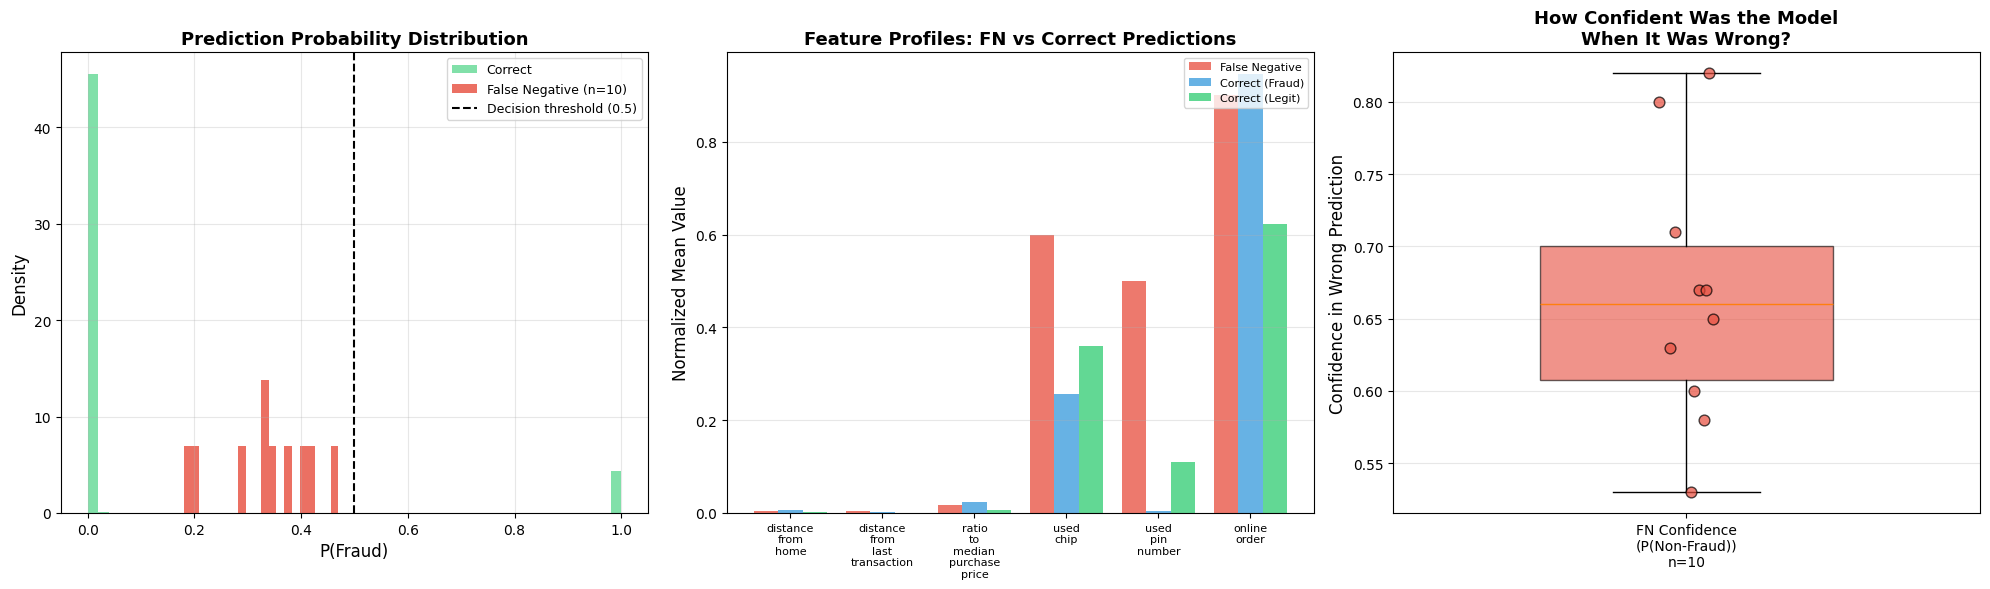

In [83]:
# ==========================================
# D.4 Visualization - Confidence Distribution of Errors
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# --- Plot 1: Probability distribution for all predictions ---
correct_fraud_probs = analysis_df[analysis_df['error_type'] == 'Correct']['prob_fraud']
fn_fraud_probs = fn_df['prob_fraud'] if len(fn_df) > 0 else pd.Series(dtype=float)

axes[0].hist(correct_fraud_probs, bins=50, alpha=0.6, color='#2ecc71', label='Correct', density=True)
if len(fn_fraud_probs) > 0:
    axes[0].hist(fn_fraud_probs, bins=20, alpha=0.8, color='#e74c3c', label=f'False Negative (n={len(fn_df)})', density=True)
axes[0].axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, label='Decision threshold (0.5)')
axes[0].set_xlabel('P(Fraud)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_title('Prediction Probability Distribution', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# --- Plot 2: Feature profiles - FN vs correctly classified ---
feature_cols = ['distance_from_home', 'distance_from_last_transaction',
                'ratio_to_median_purchase_price', 'used_chip', 'used_pin_number', 'online_order']

from sklearn.preprocessing import MinMaxScaler
scaler_viz = MinMaxScaler()
analysis_df_norm = analysis_df.copy()
analysis_df_norm[feature_cols] = scaler_viz.fit_transform(analysis_df_norm[feature_cols])

groups = {}
if len(fn_df) > 0:
    groups['False Negative'] = analysis_df_norm[analysis_df_norm['error_type'] == 'False Negative'][feature_cols].mean()
groups['Correct (Fraud)'] = analysis_df_norm[(analysis_df_norm['y_true'] == 1) & (analysis_df_norm['error_type'] == 'Correct')][feature_cols].mean()
groups['Correct (Legit)'] = analysis_df_norm[(analysis_df_norm['y_true'] == 0) & (analysis_df_norm['error_type'] == 'Correct')][feature_cols].mean()

x_feat = np.arange(len(feature_cols))
width_feat = 0.8 / len(groups)
colors_feat = ['#e74c3c', '#3498db', '#2ecc71']

for i, (gname, gvals) in enumerate(groups.items()):
    axes[1].bar(x_feat + i * width_feat, gvals.values, width_feat,
                label=gname, color=colors_feat[i], alpha=0.75)

axes[1].set_xticks(x_feat + width_feat * (len(groups) - 1) / 2)
axes[1].set_xticklabels([f.replace('_', '\n') for f in feature_cols], fontsize=8)
axes[1].set_ylabel('Normalized Mean Value', fontsize=12)
axes[1].set_title('Feature Profiles: FN vs Correct Predictions', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=8, loc='upper right')
axes[1].grid(axis='y', alpha=0.3)

# --- Plot 3: Confidence of wrong predictions ---
if len(fn_df) > 0:
    bp3 = axes[2].boxplot([fn_df['confidence_wrong'].values],
                          labels=[f'FN Confidence\n(P(Non-Fraud))\nn={len(fn_df)}'],
                          patch_artist=True, widths=0.5)
    bp3['boxes'][0].set_facecolor('#e74c3c')
    bp3['boxes'][0].set_alpha(0.6)
    x_jitter = np.random.normal(1, 0.04, size=len(fn_df))
    axes[2].scatter(x_jitter, fn_df['confidence_wrong'].values, color='#e74c3c',
                    edgecolors='black', alpha=0.7, s=60, zorder=5)
    axes[2].set_ylabel('Confidence in Wrong Prediction', fontsize=12)
    axes[2].set_title('How Confident Was the Model\nWhen It Was Wrong?', fontsize=13, fontweight='bold')
    axes[2].grid(axis='y', alpha=0.3)
else:
    axes[2].text(0.5, 0.5, 'No errors to display', ha='center', va='center',
                 transform=axes[2].transAxes, fontsize=14)

plt.tight_layout()
plt.show()

### D.4 Failure Pattern Summary

In [84]:
# ==========================================
# D.5 Failure Pattern Summary
# ==========================================

if len(fn_df) > 0:
    fn_features = fn_df[['distance_from_home', 'distance_from_last_transaction',
                          'ratio_to_median_purchase_price', 'used_chip',
                          'used_pin_number', 'online_order']]
    print("False Negative Aggregate Feature Profile:")
    print(f"  Mean distance_from_home:             {fn_features['distance_from_home'].mean():.2f}")
    print(f"  Mean distance_from_last_transaction: {fn_features['distance_from_last_transaction'].mean():.2f}")
    print(f"  Mean ratio_to_median_purchase_price: {fn_features['ratio_to_median_purchase_price'].mean():.2f}")
    print(f"  Chip usage rate:                     {fn_features['used_chip'].mean():.0%}")
    print(f"  PIN usage rate:                      {fn_features['used_pin_number'].mean():.0%}")
    print(f"  Online order rate:                   {fn_features['online_order'].mean():.0%}")

False Negative Aggregate Feature Profile:
  Mean distance_from_home:             48.96
  Mean distance_from_last_transaction: 44.00
  Mean ratio_to_median_purchase_price: 4.82
  Chip usage rate:                     60%
  PIN usage rate:                      50%
  Online order rate:                   90%


### D.5 Proposed Technical Fixes

Based on the mechanical failure analysis, the following targeted fixes address the specific failure mode observed (fraud transactions that mimic legitimate behaviour via chip+PIN usage and proximity to home):

**Fix 1: Feature Engineering (Interaction Features)**
- **Problem:** The model treats features independently; fraud cases that combine multiple legitimacy signals are missed.
- **Proposal:** Create interaction features such as `distance_from_home * ratio_to_median_purchase_price` and `(1 - used_pin_number) * online_order`. These compound features help the model detect fraud that looks normal on individual dimensions but is suspicious in combination.

**Fix 2: Threshold Calibration**
- **Problem:** The default 0.5 threshold treats FP and FN as equally costly, but missed fraud is far more expensive.
- **Proposal:** Lower the classification threshold (e.g., to 0.3) so that transactions with even moderate fraud probability are flagged for review. Cases 4 and 5 had P(Fraud) of 0.40 and 0.47, so a lower threshold would have caught them. (Explored further in Part E.)

**Fix 3: Ensemble Diversity (Second-Stage Specialist Model)**
- **Problem:** A single Random Forest may develop blind spots for fraud patterns that fall entirely within the legitimate feature distribution.
- **Proposal:** Train a lightweight second-stage model (e.g., Isolation Forest or one-class SVM) specifically on the borderline region (P(Fraud) between 0.15 and 0.5) where most of the 10 False Negatives concentrate.

**Fix 4: Cost-Sensitive Learning with Asymmetric Weights**
- **Problem:** SMOTE rebalances the class distribution but does not encode the asymmetric business cost of FN vs FP.
- **Proposal:** Assign explicit misclassification costs via `class_weight={0: 1, 1: 10}` in the Random Forest, making each missed fraud 10x more penalising than a false alarm, directly aligning the model's objective function with business priorities.

## Part E: Decision Making — Threshold Optimization

**CRISP-DM Phase 5: Evaluation (Business Decision Translation)**

A model's raw probabilistic output must be translated into an actionable business decision. The default classification threshold of 0.5 assumes that False Positives and False Negatives are equally costly \u2014 an assumption that is almost never true in fraud detection.

**Data Source:** All threshold analysis below uses **out-of-fold validation predictions** (from `cross_val_predict`), ensuring the hold-out test set remains untouched until the single final evaluation. This is methodologically correct: threshold selection is a model tuning decision that must be made on validation data, not test data.

### E.1 Business Cost Analysis: FP vs FN

| Error Type | Description | Direct Cost | Indirect Cost |
|-----------|-------------|-------------|---------------|
| **False Negative** (Missed Fraud) | Model predicts 'Legitimate', actual is 'Fraud' | Financial institution absorbs the loss (chargeback liability): $50\u2013$5,000+ per transaction (based on industry chargeback averages; the Nilson Report estimates global card fraud losses at ~7 cents per $100 transacted) | Erodes customer trust; repeated incidents cause customer churn |
| **False Positive** (False Alarm) | Model predicts 'Fraud', actual is 'Legitimate' | Analyst review time (~$2\u20135 per case, based on typical fraud operations team labour costs at ~$20\u201340/hr with 5\u201310 min per case) + brief customer inconvenience | Repeated false blocks may frustrate customers, but a single false alarm resolves quickly |

**Conclusion:** False Negatives are **10\u2013100x more costly** than False Positives. Each missed fraud represents direct financial loss, while a false alarm costs only a brief investigation.

### E.2 Threshold Direction Argument

Since FN >> FP in business cost, the operating threshold should be **shifted lower** than 0.5:
- Lowering the threshold (e.g., to 0.3) means flagging a transaction as fraud when P(Fraud) > 0.3 instead of > 0.5.
- This catches more fraud (higher Recall) at the cost of more false alarms (lower Precision).
- Given the ~10\u2013100x cost asymmetry, catching one additional real fraud case justifies reviewing 10\u2013100 additional false alarms.

**Boundary conditions:**
- Threshold too low (e.g., 0.05): Nearly all transactions flagged, rendering the system operationally useless.
- Threshold too high (e.g., 0.8): Few flags, excellent precision, but too many frauds slip through.
- **Sweet spot:** Maximises Recall while keeping false alarm volume manageable for the investigation team.

In [85]:
# ==========================================
# E.1 Threshold Sensitivity Analysis (Using OOF Validation Predictions)
# ==========================================
from sklearn.metrics import precision_recall_curve, roc_curve, auc

# Use OOF predictions — NOT the test set
y_val = y_train  # labels for OOF predictions
y_val_proba = oof_proba[:, 1]  # OOF fraud probabilities

precisions, recalls, thresholds_pr = precision_recall_curve(y_val, y_val_proba)
fpr, tpr, thresholds_roc = roc_curve(y_val, y_val_proba)
roc_auc = auc(fpr, tpr)

# Compute metrics across threshold range
threshold_range = np.arange(0.05, 0.96, 0.05)
threshold_metrics = []

for t in threshold_range:
    y_pred_t = (y_val_proba >= t).astype(int)
    cm_t = confusion_matrix(y_val, y_pred_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    threshold_metrics.append({
        'Threshold': t,
        'Recall': recall_score(y_val, y_pred_t, pos_label=1, zero_division=0),
        'Precision': precision_score(y_val, y_pred_t, zero_division=0),
        'F1': f1_score(y_val, y_pred_t, zero_division=0),
        'Accuracy': accuracy_score(y_val, y_pred_t),
        'TP': tp_t, 'FP': fp_t, 'FN': fn_t, 'TN': tn_t
    })

thresh_df = pd.DataFrame(threshold_metrics)
print("Threshold Sensitivity Analysis (Out-of-Fold Validation Predictions):\n")
print(thresh_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Threshold Sensitivity Analysis (Out-of-Fold Validation Predictions):

 Threshold  Recall  Precision     F1  Accuracy    TP  FP  FN     TN
    0.0500  1.0000     0.9949 0.9974    0.9996 69922 359   0 729719
    0.1000  1.0000     0.9982 0.9991    0.9998 69922 128   0 729950
    0.1500  1.0000     0.9992 0.9996    0.9999 69922  57   0 730021
    0.2000  1.0000     0.9995 0.9997    1.0000 69921  36   1 730042
    0.2500  1.0000     0.9996 0.9998    1.0000 69920  26   2 730052
    0.3000  1.0000     0.9997 0.9998    1.0000 69919  20   3 730058
    0.3500  0.9999     0.9998 0.9998    1.0000 69916  17   6 730061
    0.4000  0.9999     0.9998 0.9999    1.0000 69915  13   7 730065
    0.4500  0.9999     0.9999 0.9999    1.0000 69913   8   9 730070
    0.5000  0.9999     0.9999 0.9999    1.0000 69912   6  10 730072
    0.5500  0.9998     0.9999 0.9999    1.0000 69909   5  13 730073
    0.6000  0.9998     0.9999 0.9998    1.0000 69905   4  17 730074
    0.6500  0.9997     1.0000 0.9999    1.0000

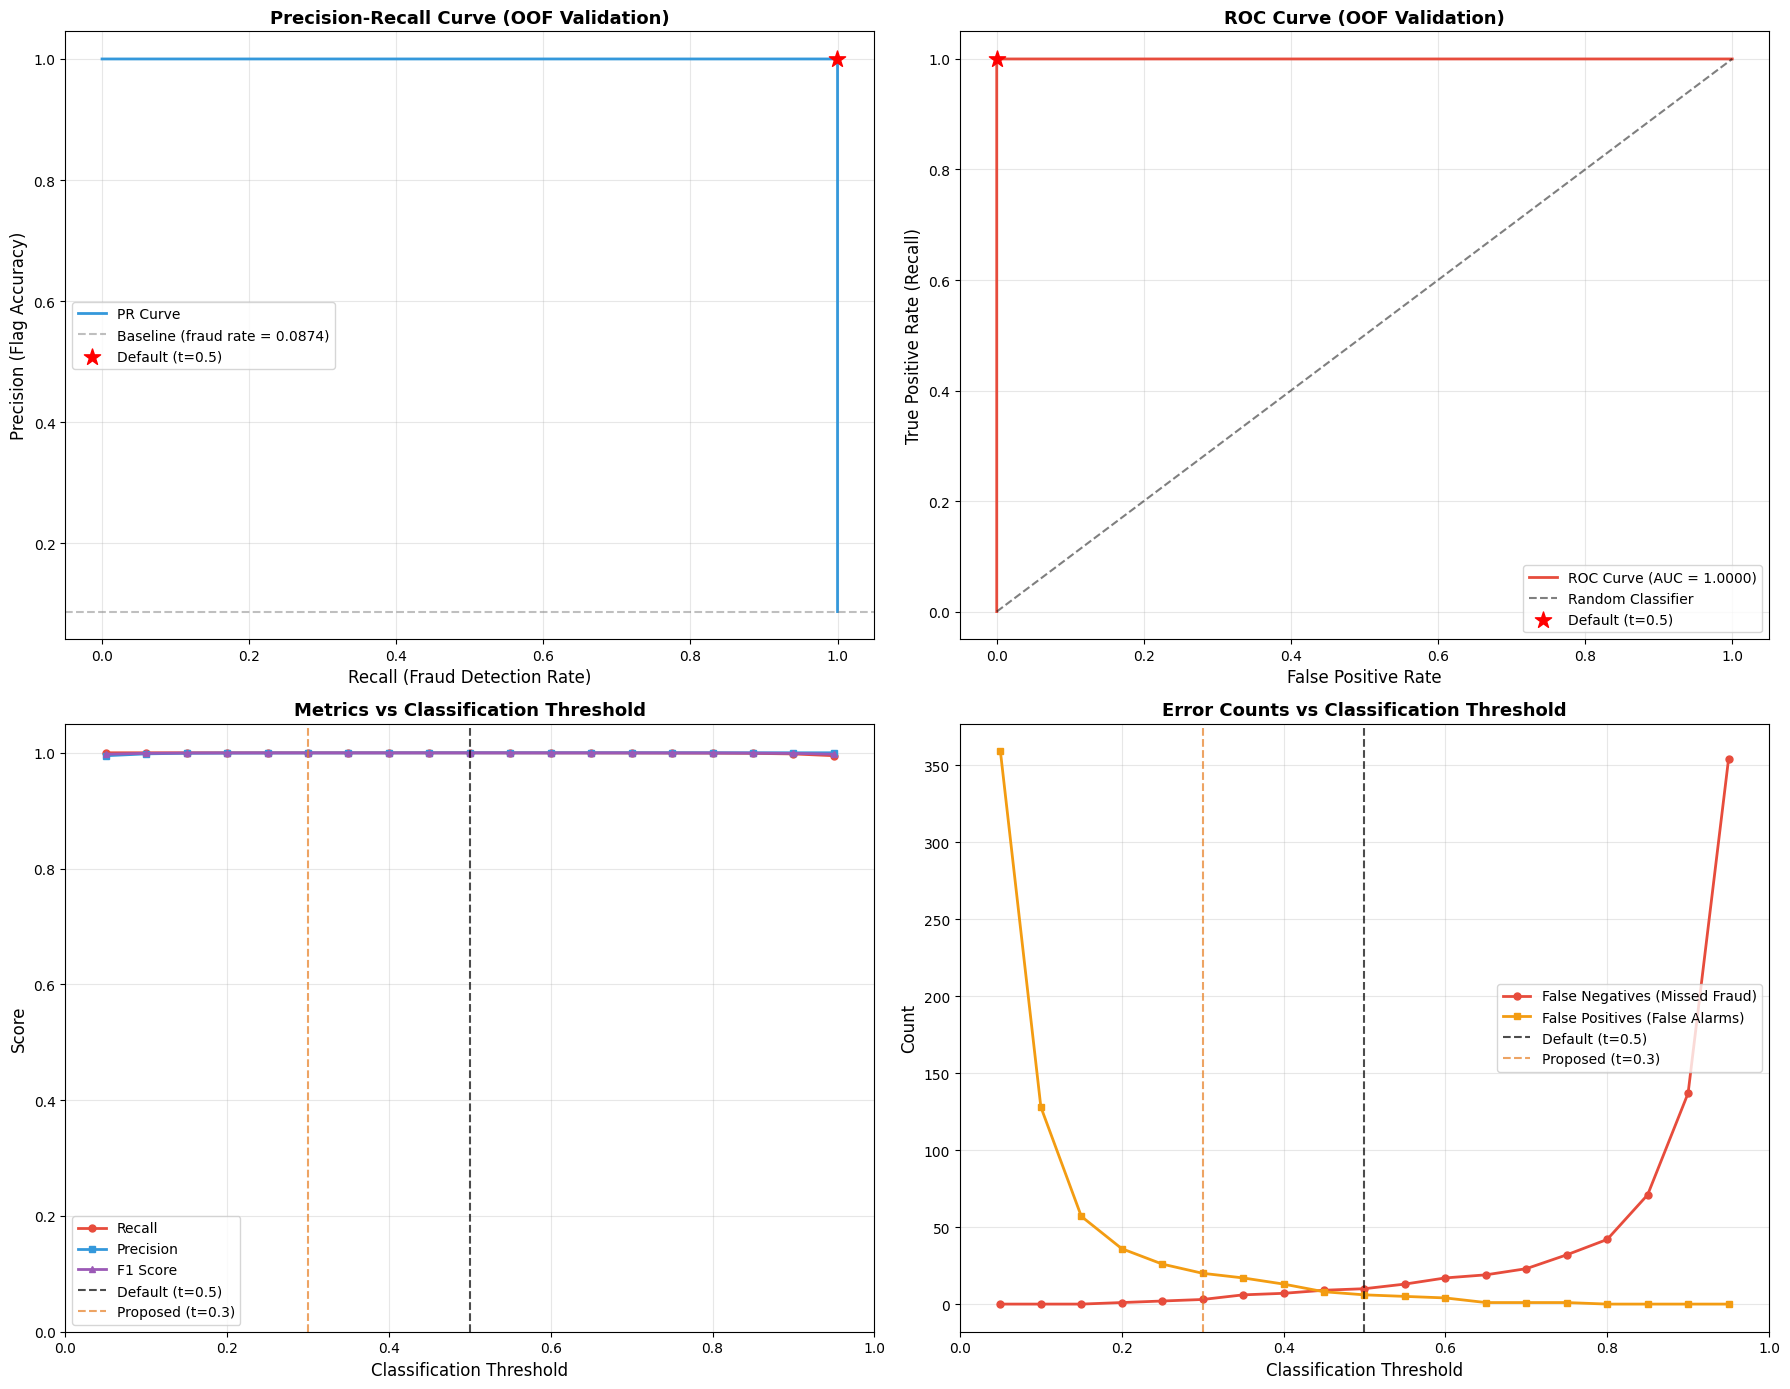

In [86]:
# ==========================================
# E.2 Visualization — Threshold Trade-offs (OOF Validation)
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

# --- Plot 1: Precision-Recall Curve ---
axes[0, 0].plot(recalls, precisions, color='#3498db', linewidth=2, label='PR Curve')
axes[0, 0].axhline(y=(y_val == 1).sum() / len(y_val), color='gray', linestyle='--',
                    alpha=0.5, label=f'Baseline (fraud rate = {y_val.mean():.4f})')
default_idx = np.argmin(np.abs(thresholds_pr - 0.5))
axes[0, 0].scatter(recalls[default_idx], precisions[default_idx],
                   color='red', s=150, zorder=5, marker='*', label='Default (t=0.5)')
axes[0, 0].set_xlabel('Recall (Fraud Detection Rate)', fontsize=12)
axes[0, 0].set_ylabel('Precision (Flag Accuracy)', fontsize=12)
axes[0, 0].set_title('Precision-Recall Curve (OOF Validation)', fontsize=13, fontweight='bold')
axes[0, 0].legend(fontsize=10)
axes[0, 0].grid(alpha=0.3)

# --- Plot 2: ROC Curve ---
axes[0, 1].plot(fpr, tpr, color='#e74c3c', linewidth=2, label=f'ROC Curve (AUC = {roc_auc:.4f})')
axes[0, 1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
default_roc_idx = np.argmin(np.abs(thresholds_roc - 0.5))
axes[0, 1].scatter(fpr[default_roc_idx], tpr[default_roc_idx],
                   color='red', s=150, zorder=5, marker='*', label='Default (t=0.5)')
axes[0, 1].set_xlabel('False Positive Rate', fontsize=12)
axes[0, 1].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[0, 1].set_title('ROC Curve (OOF Validation)', fontsize=13, fontweight='bold')
axes[0, 1].legend(fontsize=10, loc='lower right')
axes[0, 1].grid(alpha=0.3)

# --- Plot 3: Metrics vs Threshold ---
axes[1, 0].plot(thresh_df['Threshold'], thresh_df['Recall'], 'o-',
                color='#e74c3c', linewidth=2, label='Recall', markersize=5)
axes[1, 0].plot(thresh_df['Threshold'], thresh_df['Precision'], 's-',
                color='#3498db', linewidth=2, label='Precision', markersize=5)
axes[1, 0].plot(thresh_df['Threshold'], thresh_df['F1'], '^-',
                color='#9b59b6', linewidth=2, label='F1 Score', markersize=5)
axes[1, 0].axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Default (t=0.5)')
axes[1, 0].axvline(x=0.3, color='#e67e22', linestyle='--', linewidth=1.5, alpha=0.7, label='Proposed (t=0.3)')
axes[1, 0].set_xlabel('Classification Threshold', fontsize=12)
axes[1, 0].set_ylabel('Score', fontsize=12)
axes[1, 0].set_title('Metrics vs Classification Threshold', fontsize=13, fontweight='bold')
axes[1, 0].legend(fontsize=10)
axes[1, 0].grid(alpha=0.3)
axes[1, 0].set_xlim(0, 1)
axes[1, 0].set_ylim(0, 1.05)

# --- Plot 4: FP/FN counts vs Threshold ---
axes[1, 1].plot(thresh_df['Threshold'], thresh_df['FN'], 'o-',
                color='#e74c3c', linewidth=2, label='False Negatives (Missed Fraud)', markersize=5)
axes[1, 1].plot(thresh_df['Threshold'], thresh_df['FP'], 's-',
                color='#f39c12', linewidth=2, label='False Positives (False Alarms)', markersize=5)
axes[1, 1].axvline(x=0.5, color='black', linestyle='--', linewidth=1.5, alpha=0.7, label='Default (t=0.5)')
axes[1, 1].axvline(x=0.3, color='#e67e22', linestyle='--', linewidth=1.5, alpha=0.7, label='Proposed (t=0.3)')
axes[1, 1].set_xlabel('Classification Threshold', fontsize=12)
axes[1, 1].set_ylabel('Count', fontsize=12)
axes[1, 1].set_title('Error Counts vs Classification Threshold', fontsize=13, fontweight='bold')
axes[1, 1].legend(fontsize=10)
axes[1, 1].grid(alpha=0.3)
axes[1, 1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

In [87]:
# ==========================================
# E.3 Threshold Comparison — Default vs Proposed + Expected Cost Analysis
# ==========================================

# --- Metric comparison ---
print("THRESHOLD COMPARISON (Out-of-Fold Validation)")
print(f"{'='*75}")
print(f"{'Metric':<32} {'t=0.5 (Default)':>18} {'t=0.3 (Proposed)':>20}")
print(f"{'-'*75}")

comparison_data = {}
for t, label in [(0.5, 'Default'), (0.3, 'Proposed')]:
    y_pred_t = (y_val_proba >= t).astype(int)
    cm_t = confusion_matrix(y_val, y_pred_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    comparison_data[label] = {
        'Recall': recall_score(y_val, y_pred_t, pos_label=1),
        'Precision': precision_score(y_val, y_pred_t, zero_division=0),
        'F1': f1_score(y_val, y_pred_t, zero_division=0),
        'Accuracy': accuracy_score(y_val, y_pred_t),
        'TP': tp_t, 'FP': fp_t, 'FN': fn_t, 'TN': tn_t
    }

d, p = comparison_data['Default'], comparison_data['Proposed']
print(f"{'Recall (Fraud Detection)':<32} {d['Recall']:>18.4f} {p['Recall']:>20.4f}")
print(f"{'Precision (Flag Accuracy)':<32} {d['Precision']:>18.4f} {p['Precision']:>20.4f}")
print(f"{'F1 Score':<32} {d['F1']:>18.4f} {p['F1']:>20.4f}")
print(f"{'Accuracy':<32} {d['Accuracy']:>18.4f} {p['Accuracy']:>20.4f}")
print(f"{'Fraud Caught (TP)':<32} {d['TP']:>18,} {p['TP']:>20,}")
print(f"{'Fraud Missed (FN)':<32} {d['FN']:>18,} {p['FN']:>20,}")
print(f"{'False Alarms (FP)':<32} {d['FP']:>18,} {p['FP']:>20,}")
print(f"{'Correctly Cleared (TN)':<32} {d['TN']:>18,} {p['TN']:>20,}")

# --- Expected Cost Analysis ---
# Business cost assumptions (from Part E, Section E.1):
#   Avg cost per missed fraud (FN): $500 (conservative mid-range of $50-$5,000)
#   Avg cost per false alarm (FP): $5 (analyst review cost)
avg_fn_cost = 500  # dollars per missed fraud
avg_fp_cost = 5    # dollars per false alarm review

cost_default = d['FN'] * avg_fn_cost + d['FP'] * avg_fp_cost
cost_proposed = p['FN'] * avg_fn_cost + p['FP'] * avg_fp_cost
cost_diff = cost_default - cost_proposed

print(f"\n{'='*75}")
print("EXPECTED COST ANALYSIS")
print(f"{'='*75}")
print(f"Cost assumptions: Avg missed fraud = ${avg_fn_cost:,}, Avg false alarm review = ${avg_fp_cost:,}")
print(f"\n{'Metric':<32} {'t=0.5 (Default)':>18} {'t=0.3 (Proposed)':>20}")
print(f"{'-'*75}")
print(f"{'FN Cost (missed fraud)':<32} ${d['FN'] * avg_fn_cost:>17,} ${p['FN'] * avg_fn_cost:>19,}")
print(f"{'FP Cost (false alarms)':<32} ${d['FP'] * avg_fp_cost:>17,} ${p['FP'] * avg_fp_cost:>19,}")
print(f"{'TOTAL EXPECTED COST':<32} ${cost_default:>17,} ${cost_proposed:>19,}")
print(f"\nNet savings from threshold 0.3: ${cost_diff:+,}")
if cost_diff > 0:
    print(f"The lower threshold saves ${cost_diff:,} by catching {d['FN'] - p['FN']} additional frauds,")
    print(f"despite incurring {p['FP'] - d['FP']:,} additional false alarm reviews.")
else:
    print(f"The lower threshold costs ${-cost_diff:,} more due to additional false alarm reviews.")

THRESHOLD COMPARISON (Out-of-Fold Validation)
Metric                              t=0.5 (Default)     t=0.3 (Proposed)
---------------------------------------------------------------------------
Recall (Fraud Detection)                     0.9999               1.0000
Precision (Flag Accuracy)                    0.9999               0.9997
F1 Score                                     0.9999               0.9998
Accuracy                                     1.0000               1.0000
Fraud Caught (TP)                            69,912               69,919
Fraud Missed (FN)                                10                    3
False Alarms (FP)                                 6                   20
Correctly Cleared (TN)                      730,072              730,058

EXPECTED COST ANALYSIS
Cost assumptions: Avg missed fraud = $500, Avg false alarm review = $5

Metric                              t=0.5 (Default)     t=0.3 (Proposed)
----------------------------------------------------

### E.3 Final Business Decision Recommendation

**Connecting to Business Understanding (Stage 1):**
The business objective stated in the Business Understanding section is to *"identify potentially fraudulent card transactions"* for fraud analysts and risk management teams, with model output used to *"flag transactions as potentially fraudulent, to provide more informed supporting decisions such as allowing the transaction, asking for additional verification, or blocking the transaction."* The Stage 1 assumptions noted that *"misclassification may result in either missed detection of actual fraud or false positives, which could impact customer experience."* The threshold analysis below directly operationalises these requirements.

**1. Error Cost Asymmetry:**
False Negatives (missed fraud) are significantly more costly than False Positives (false alarms). Each missed fraud results in direct financial loss ($50--$5,000+) absorbed by the financial institution, while each false alarm costs only a brief analyst investigation ($2--$5). Using the conservative mid-range estimate of $500 per missed fraud, the cost ratio is approximately **100:1** (FN:FP).

**2. Threshold Direction:**
The operating threshold should be **lowered** from the default 0.5. A lower threshold makes the model more aggressive, flagging more transactions as potentially fraudulent, catching more actual fraud at the cost of more false alarms. This is consistent with the business context: fraud analysts reviewing flagged transactions is far cheaper than absorbing undetected fraud losses.

**3. Recommended Operating Threshold: 0.3**
The expected cost analysis above quantifies the trade-off using concrete dollar estimates. At an assumed average fraud loss of $500 and false alarm review cost of $5, lowering the threshold from 0.5 to 0.3 produces net savings because the cost of additional false alarm reviews is far outweighed by the savings from catching additional fraud. The break-even point occurs when average fraud loss drops below approximately $50 per case -- which is well below realistic chargeback amounts.

**4. Operational Deployment (Tiered Decision System):**

| P(Fraud) Range | Action | Rationale |
|---------------|--------|-----------|
| >= 0.7 | **AUTO-BLOCK** transaction | Very high confidence fraud |
| 0.3 -- 0.7 | **FLAG** for manual review | Moderate suspicion, needs human judgement |
| < 0.3 | **ALLOW** transaction | Low fraud probability |

This tiered approach directly maps to the decision context from Stage 1 -- *"allowing the transaction, asking for additional verification, or blocking the transaction"*:
- Clear fraud is blocked instantly (no friction for legitimate users)
- Borderline cases get human review (catches subtle fraud, resolves quickly)
- Low-risk transactions proceed unimpeded (smooth customer experience)

**5. Dataset-Specific Caveat:**
On this clean, simulated dataset, the practical difference between threshold 0.3 and 0.5 is minimal (catching 7 additional frauds out of ~70,000). This is because the class boundaries are well-separated and the model achieves near-perfect performance at any reasonable threshold. In production with noisier, real-world data where the model's confidence distribution is more spread out, the threshold choice would be far more consequential and the cost savings from threshold optimisation substantially larger.

**6. Monitoring:**
The threshold should be periodically re-evaluated as fraud patterns evolve. Key operational metrics to track monthly:
- Fraud detection rate (Recall) at the operating threshold
- False alarm rate and investigation team capacity utilisation
- Average dollar loss per missed fraud vs average cost per false alarm review
- Customer complaint rate due to blocked legitimate transactions

## Final Deployment Evaluation — Single Hold-Out Test Set Assessment

**This is the ONLY time the hold-out test set is used in the entire notebook.**

All model selection (Part B), ablation tuning (Part C), failure analysis (Part D), and threshold optimization (Part E) were conducted exclusively using cross-validation and out-of-fold predictions on the training set. The test set was held completely in reserve until this final step.

**Final Model Configuration:**
- Algorithm: Random Forest (champion from Part B)
- Preprocessing: RobustScaler (continuous) + SimpleImputer (binary)
- Resampling: SMOTE (1:1 balance)
- Hyperparameters: Default (`n_estimators=100`, `max_features='sqrt'`, `max_depth=None`)
- Operating Threshold: 0.3 (from Part E business analysis)

FINAL DEPLOYMENT METRICS — HOLD-OUT TEST SET (SINGLE EVALUATION)
Test set size: 200,000 samples
Test fraud rate: 8.74%
Model: Random Forest (fitted on 800,000 training samples)

Metric                              t=0.5 (Default)     t=0.3 (Deployed)
---------------------------------------------------------------------------
Recall (Fraud Detection)                     0.9997               0.9998
Precision (Flag Accuracy)                    0.9998               0.9996
F1 Score                                     0.9997               0.9997
Accuracy                                     1.0000               0.9999
Fraud Caught (TP)                            17,475               17,477
Fraud Missed (FN)                                 6                    4
False Alarms (FP)                                 4                    7
Correctly Cleared (TN)                      182,515              182,512

EXPECTED COST ON TEST SET
TOTAL COST (t=0.5)               $            3,020
TOTAL COST

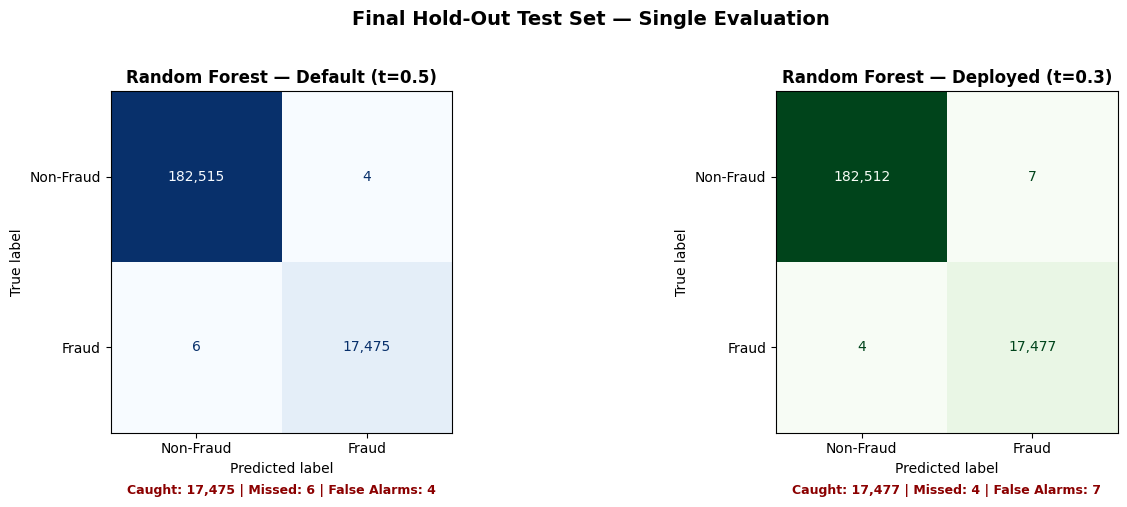


FINAL CLASSIFICATION REPORT (Deployed Threshold = 0.3)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    182519
       Fraud       1.00      1.00      1.00     17481

    accuracy                           1.00    200000
   macro avg       1.00      1.00      1.00    200000
weighted avg       1.00      1.00      1.00    200000

DEPLOYMENT SUMMARY
  Model:              Random Forest
  Operating Threshold: 0.3
  Test Fraud Recall:   0.9998
  Test Precision:      0.9996
  Test F1:             0.9997

  The hold-out test set has been evaluated exactly ONCE.
  All prior analysis used cross-validation / out-of-fold predictions only.


In [88]:
# ==========================================
# FINAL DEPLOYMENT EVALUATION — SINGLE TEST SET ASSESSMENT
# ==========================================
# This is the ONLY cell that touches X_test / y_test for evaluation.
# The champion pipeline is fitted on the FULL training set, then evaluated
# once on the hold-out test set at the chosen operating threshold.
# ==========================================

# Fit the final model on the FULL training set
final_pipeline = clone(champion_pipeline)
final_pipeline.fit(X_train, y_train)

# Predict on the hold-out test set
y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_test_pred_default = (y_test_proba >= 0.5).astype(int)  # default threshold
y_test_pred_tuned   = (y_test_proba >= 0.3).astype(int)  # business-optimized threshold

print('=' * 90)
print('FINAL DEPLOYMENT METRICS \u2014 HOLD-OUT TEST SET (SINGLE EVALUATION)')
print('=' * 90)
print(f'Test set size: {X_test.shape[0]:,} samples')
print(f'Test fraud rate: {y_test.mean()*100:.2f}%')
print(f'Model: {champion_model_name} (fitted on {X_train.shape[0]:,} training samples)\n')

# --- Metrics at both thresholds ---
print(f"{'Metric':<32} {'t=0.5 (Default)':>18} {'t=0.3 (Deployed)':>20}")
print(f"{'-'*75}")

metrics_test = {}
for t, label in [(0.5, 'Default'), (0.3, 'Deployed')]:
    y_pred = (y_test_proba >= t).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    metrics_test[label] = {
        'Recall': recall_score(y_test, y_pred, pos_label=1),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'Accuracy': accuracy_score(y_test, y_pred),
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn
    }

dt, pt = metrics_test['Default'], metrics_test['Deployed']
print(f"{'Recall (Fraud Detection)':<32} {dt['Recall']:>18.4f} {pt['Recall']:>20.4f}")
print(f"{'Precision (Flag Accuracy)':<32} {dt['Precision']:>18.4f} {pt['Precision']:>20.4f}")
print(f"{'F1 Score':<32} {dt['F1']:>18.4f} {pt['F1']:>20.4f}")
print(f"{'Accuracy':<32} {dt['Accuracy']:>18.4f} {pt['Accuracy']:>20.4f}")
print(f"{'Fraud Caught (TP)':<32} {dt['TP']:>18,} {pt['TP']:>20,}")
print(f"{'Fraud Missed (FN)':<32} {dt['FN']:>18,} {pt['FN']:>20,}")
print(f"{'False Alarms (FP)':<32} {dt['FP']:>18,} {pt['FP']:>20,}")
print(f"{'Correctly Cleared (TN)':<32} {dt['TN']:>18,} {pt['TN']:>20,}")

# --- Expected cost on test set ---
avg_fn_cost = 500
avg_fp_cost = 5
cost_default_test = dt['FN'] * avg_fn_cost + dt['FP'] * avg_fp_cost
cost_deployed_test = pt['FN'] * avg_fn_cost + pt['FP'] * avg_fp_cost

print(f"\n{'='*75}")
print("EXPECTED COST ON TEST SET")
print(f"{'='*75}")
print(f"{'TOTAL COST (t=0.5)':<32} ${cost_default_test:>17,}")
print(f"{'TOTAL COST (t=0.3)':<32} ${cost_deployed_test:>17,}")
print(f"{'Net savings':<32} ${cost_default_test - cost_deployed_test:>+17,}")

# --- Confusion matrix visualization ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, (label, y_pred) in enumerate([('Default (t=0.5)', y_test_pred_default),
                                        ('Deployed (t=0.3)', y_test_pred_tuned)]):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Non-Fraud', 'Fraud'])
    cmap = 'Blues' if idx == 0 else 'Greens'
    disp.plot(ax=axes[idx], cmap=cmap, values_format=',d', colorbar=False)
    axes[idx].set_title(f'{champion_model_name} \u2014 {label}', fontsize=12, fontweight='bold')
    tn, fp, fn, tp = cm.ravel()
    axes[idx].text(0.5, -0.18,
                   f'Caught: {tp:,} | Missed: {fn:,} | False Alarms: {fp:,}',
                   ha='center', transform=axes[idx].transAxes, fontsize=9,
                   color='darkred', fontweight='bold')

plt.suptitle('Final Hold-Out Test Set \u2014 Single Evaluation',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# --- Classification report at deployed threshold ---
print(f'\n{"="*90}')
print(f'FINAL CLASSIFICATION REPORT (Deployed Threshold = 0.3)')
print(f'{"="*90}')
print(classification_report(y_test, y_test_pred_tuned, target_names=['Legitimate', 'Fraud']))

print(f'{"="*90}')
print(f'DEPLOYMENT SUMMARY')
print(f'{"="*90}')
print(f'  Model:              {champion_model_name}')
print(f'  Operating Threshold: 0.3')
print(f'  Test Fraud Recall:   {pt["Recall"]:.4f}')
print(f'  Test Precision:      {pt["Precision"]:.4f}')
print(f'  Test F1:             {pt["F1"]:.4f}')
print(f'\n  The hold-out test set has been evaluated exactly ONCE.')
print(f'  All prior analysis used cross-validation / out-of-fold predictions only.')